In [12]:
import pathlib
import shutil

# Ensure target raw and processed directories exist inside Colab
pathlib.Path('/content/data/raw').mkdir(parents=True, exist_ok=True)
pathlib.Path('/content/data/processed').mkdir(parents=True, exist_ok=True)

# Move datasets into the correct directory path
for csv_file in ['oasis_cross-sectional.csv', 'oasis_longitudinal.csv', 'oasis1_processed.csv']:
    src = pathlib.Path(f'/content/{csv_file}')
    dst = pathlib.Path(f'/content/data/raw/{csv_file}')
    if src.exists():
        shutil.copy(str(src), str(dst))
        print(f"Copied {src} to {dst}")

# Fix ROOT, DATA_FILE, RESULTS, and FIGURES paths in main.py
main_path = pathlib.Path('main.py')
if main_path.exists():
    code = main_path.read_text()

    # Replace the incorrect root resolution path
    code = code.replace("ROOT = Path(__file__).resolve().parents[1]", "ROOT = Path('/content')")
    code = code.replace("DATA_FILE = ROOT / \"data\" / \"raw\" / \"oasis_cross-sectional.csv\"", "DATA_FILE = Path('/content/data/raw/oasis_cross-sectional.csv')")
    code = code.replace("RESULTS = ROOT / \"results\"", "RESULTS = Path('/content/results')")
    code = code.replace("FIGURES = RESULTS / \"figures\"", "FIGURES = Path('/content/results/figures')")
    code = code.replace("PROCESSED = Path('/content/data/processed')", "PROCESSED = Path('/content/data/processed')")

    main_path.write_text(code)
    print("Successfully modified path assignments in main.py!")

# Execute the main ML pipeline
!python main.py

Copied /content/oasis_cross-sectional.csv to /content/data/raw/oasis_cross-sectional.csv
Copied /content/oasis_longitudinal.csv to /content/data/raw/oasis_longitudinal.csv
Copied /content/oasis1_processed.csv to /content/data/raw/oasis1_processed.csv
Successfully modified path assignments in main.py!
OASIS-1 EXPLAINABLE ALZHEIMER'S ML PROJECT

Original dataset shape: (436, 12)
Shape after preprocessing: (235, 13)

Target distribution:
Target
0    135
1    100
Name: count, dtype: int64

Data split:
Training: 141
Validation: 47
Testing: 47

Training Logistic Regression baseline...
Training Random Forest proposed model...

MODEL COMPARISON
                              Model  Threshold  Accuracy  Precision  Sensitivity  Specificity     F1     F2  ROC_AUC
       Logistic Regression Baseline       0.50    0.8511     0.8421          0.8       0.8889 0.8205 0.8081   0.8963
Random Forest + Optimized Threshold       0.25    0.6809     0.5714          1.0       0.4444 0.7273 0.8696   0.8630

Cal

### 📝 Project Execution Summary


OASIS-1 EXPLAINABLE MACHINE LEARNING PROJECT

Dataset records after preprocessing: 235
Non-dementia records: 135
Dementia records: 100

Primary features:
Age, M/F, Educ, SES, eTIV, nWBV, ASF

Target:
CDR = 0 -> Non-Dementia
CDR > 0 -> Dementia

Baseline:
Logistic Regression

Proposed:
Class-weighted Random Forest + F2-based threshold optimization

Optimal threshold:
0.2500

Baseline ROC-AUC:
0.8963

Proposed ROC-AUC:
0.8630

Proposed sensitivity:
1.0000

Proposed specificity:
0.4444

Proposed F1:
0.7273

Proposed F2:
0.8696

Top features by permutation importance:
nWBV, Age, Educ, M/F, eTIV

SHAP:
Generated successfully

IMPORTANT:
This project is an educational/research machine-learning experiment.
It is not a clinical diagnostic system.



### 📊 Model Comparison Metrics

,Model,Threshold,Accuracy,Precision,Sensitivity,Specificity,F1,F2,ROC_AUC
0,Logistic Regression Baseline,0.50,0.851064,0.842105,0.8,0.888889,0.820513,0.808081,0.896296
1,Random Forest + Optimized Threshold,0.25,0.680851,0.571429,1.0,0.444444,0.727273,0.869565,0.862963


### 🔑 Feature Importance Metrics

,Feature,Importance,Std
0,nWBV,0.218056,0.078127
1,Age,0.036481,0.030368
2,Educ,0.025278,0.016690
3,M/F,0.008056,0.010097
4,eTIV,0.003241,0.008801
5,ASF,-0.002130,0.012481
6,SES,-0.002685,0.012276


### 🎨 Generated Figures & Plots

**Figure:** 05_confusion_matrix.png

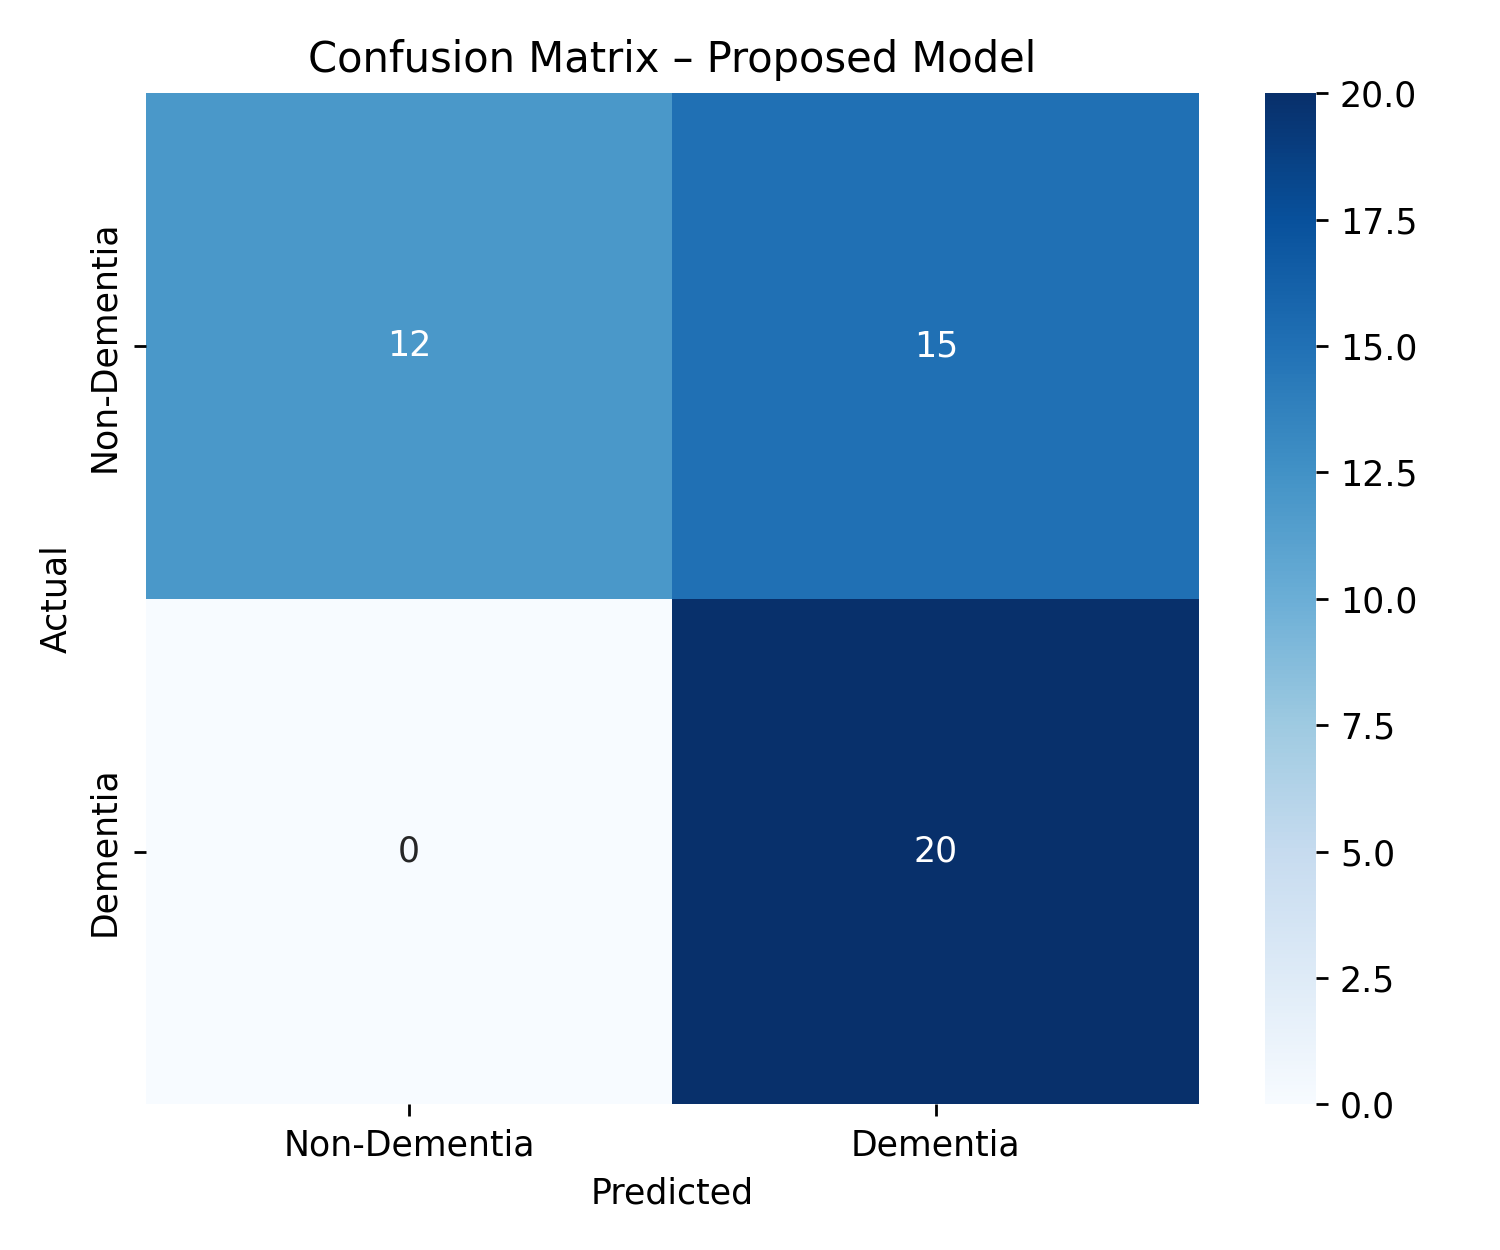

**Figure:** 03_age_vs_nwbv.png

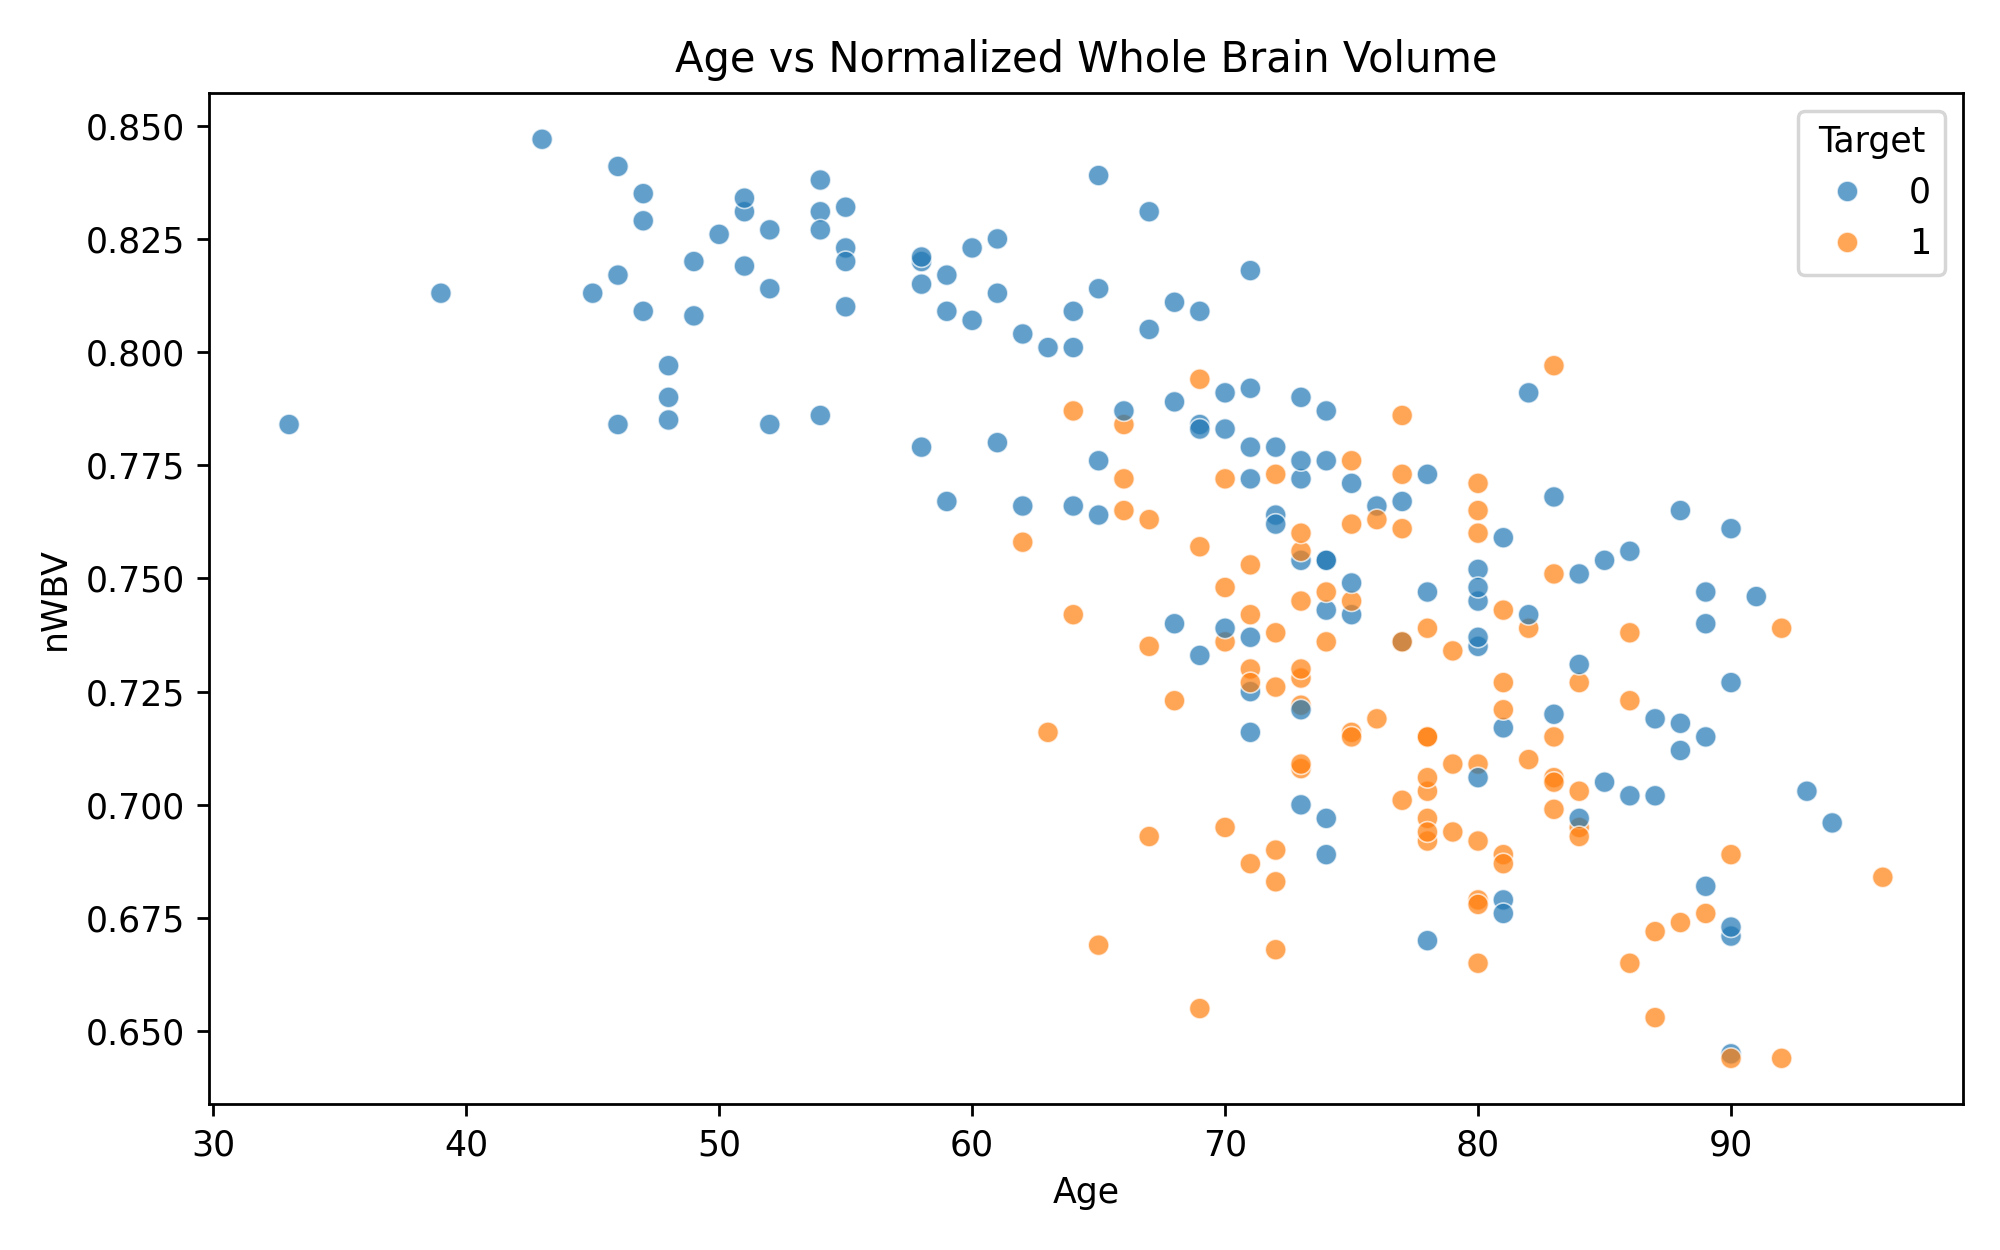

**Figure:** 06_roc_comparison.png

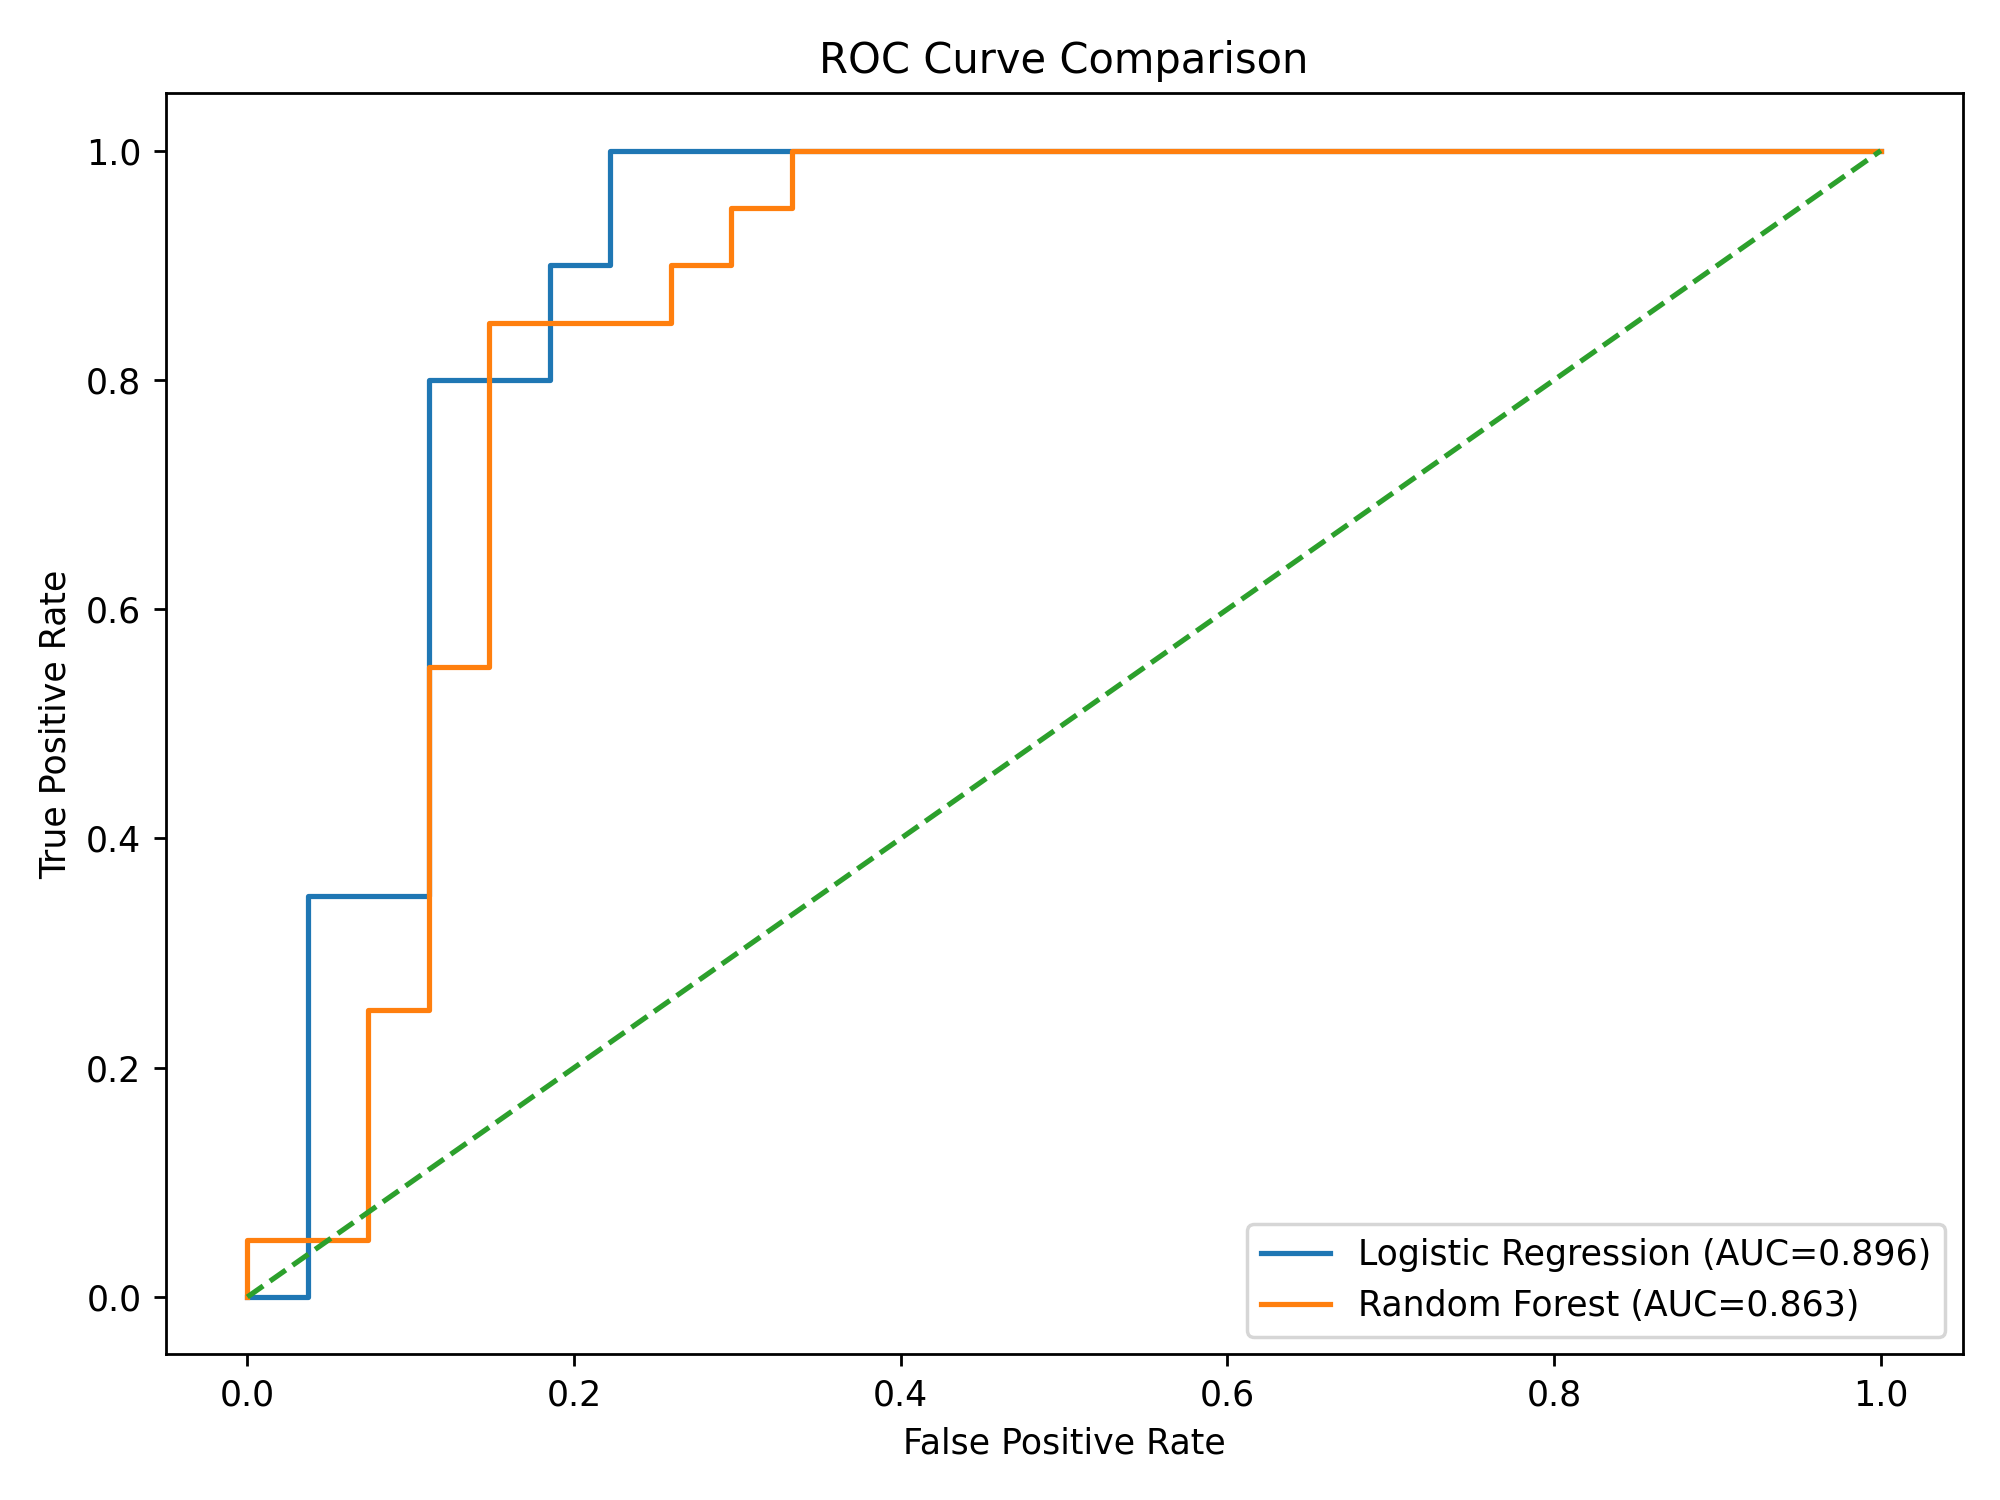

**Figure:** 07_feature_importance.png

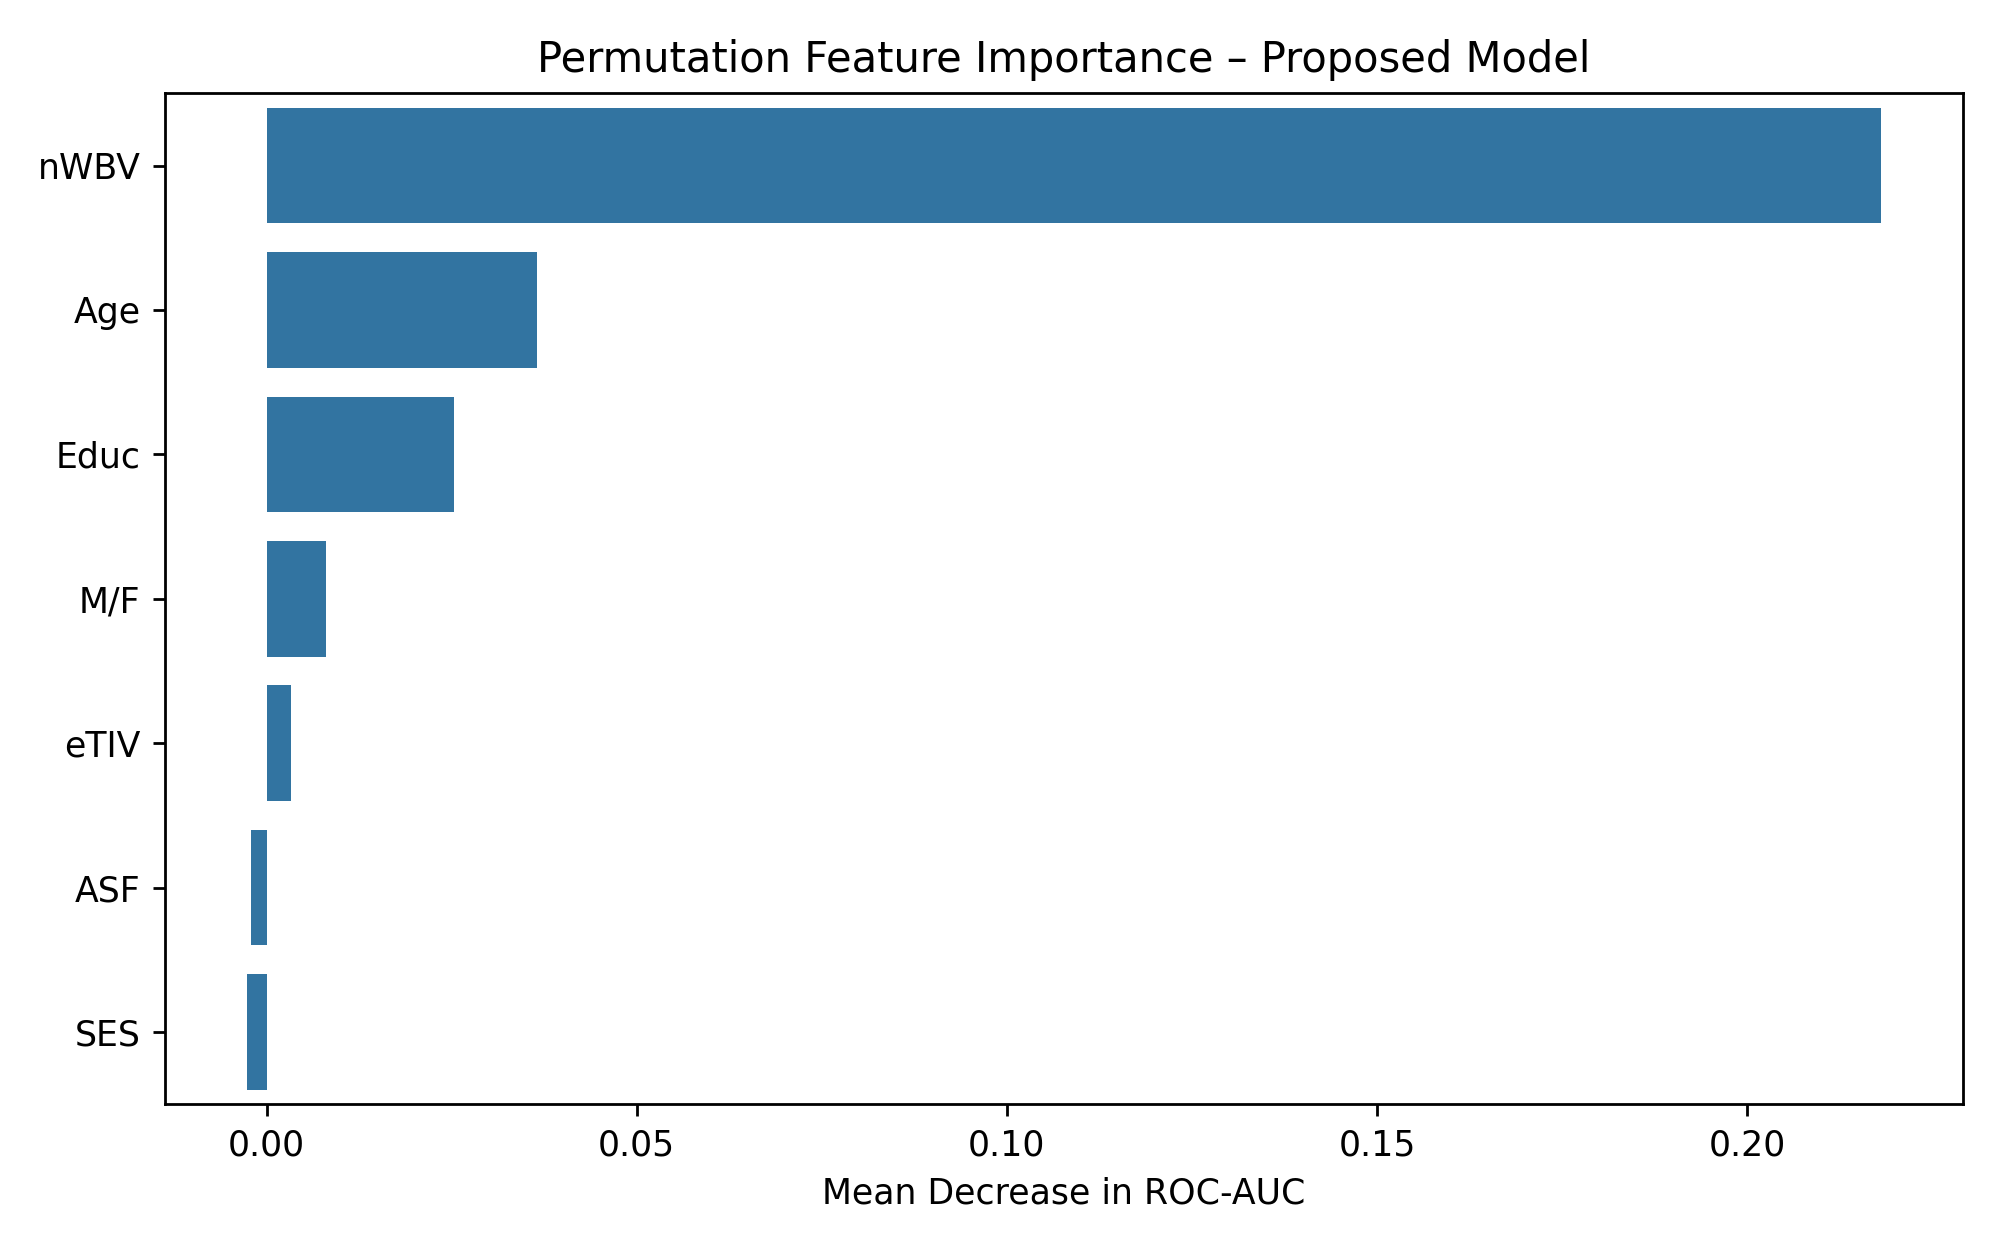

**Figure:** 04_threshold_optimization.png

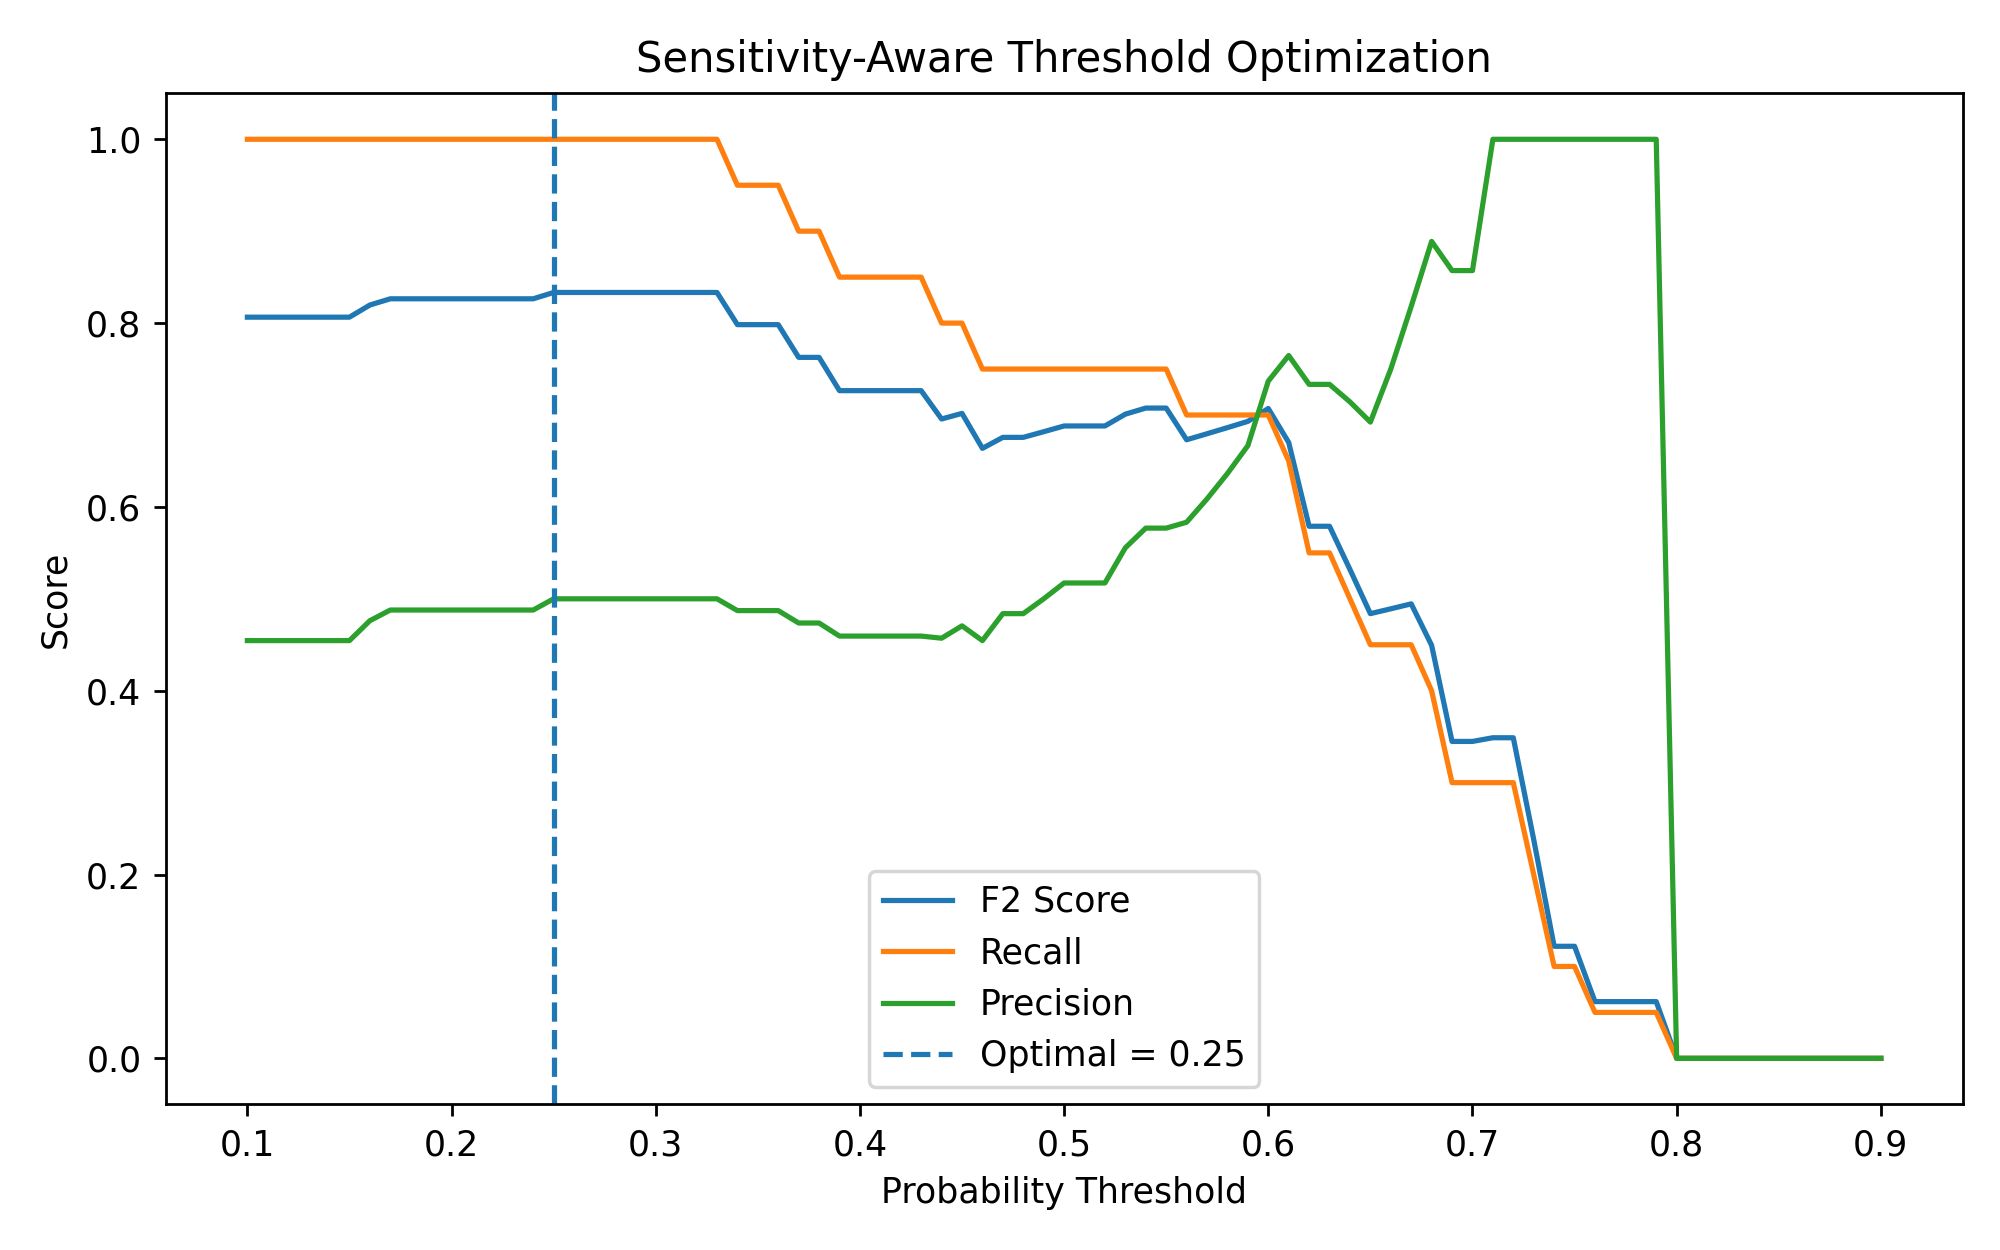

**Figure:** 02_correlation_heatmap.png

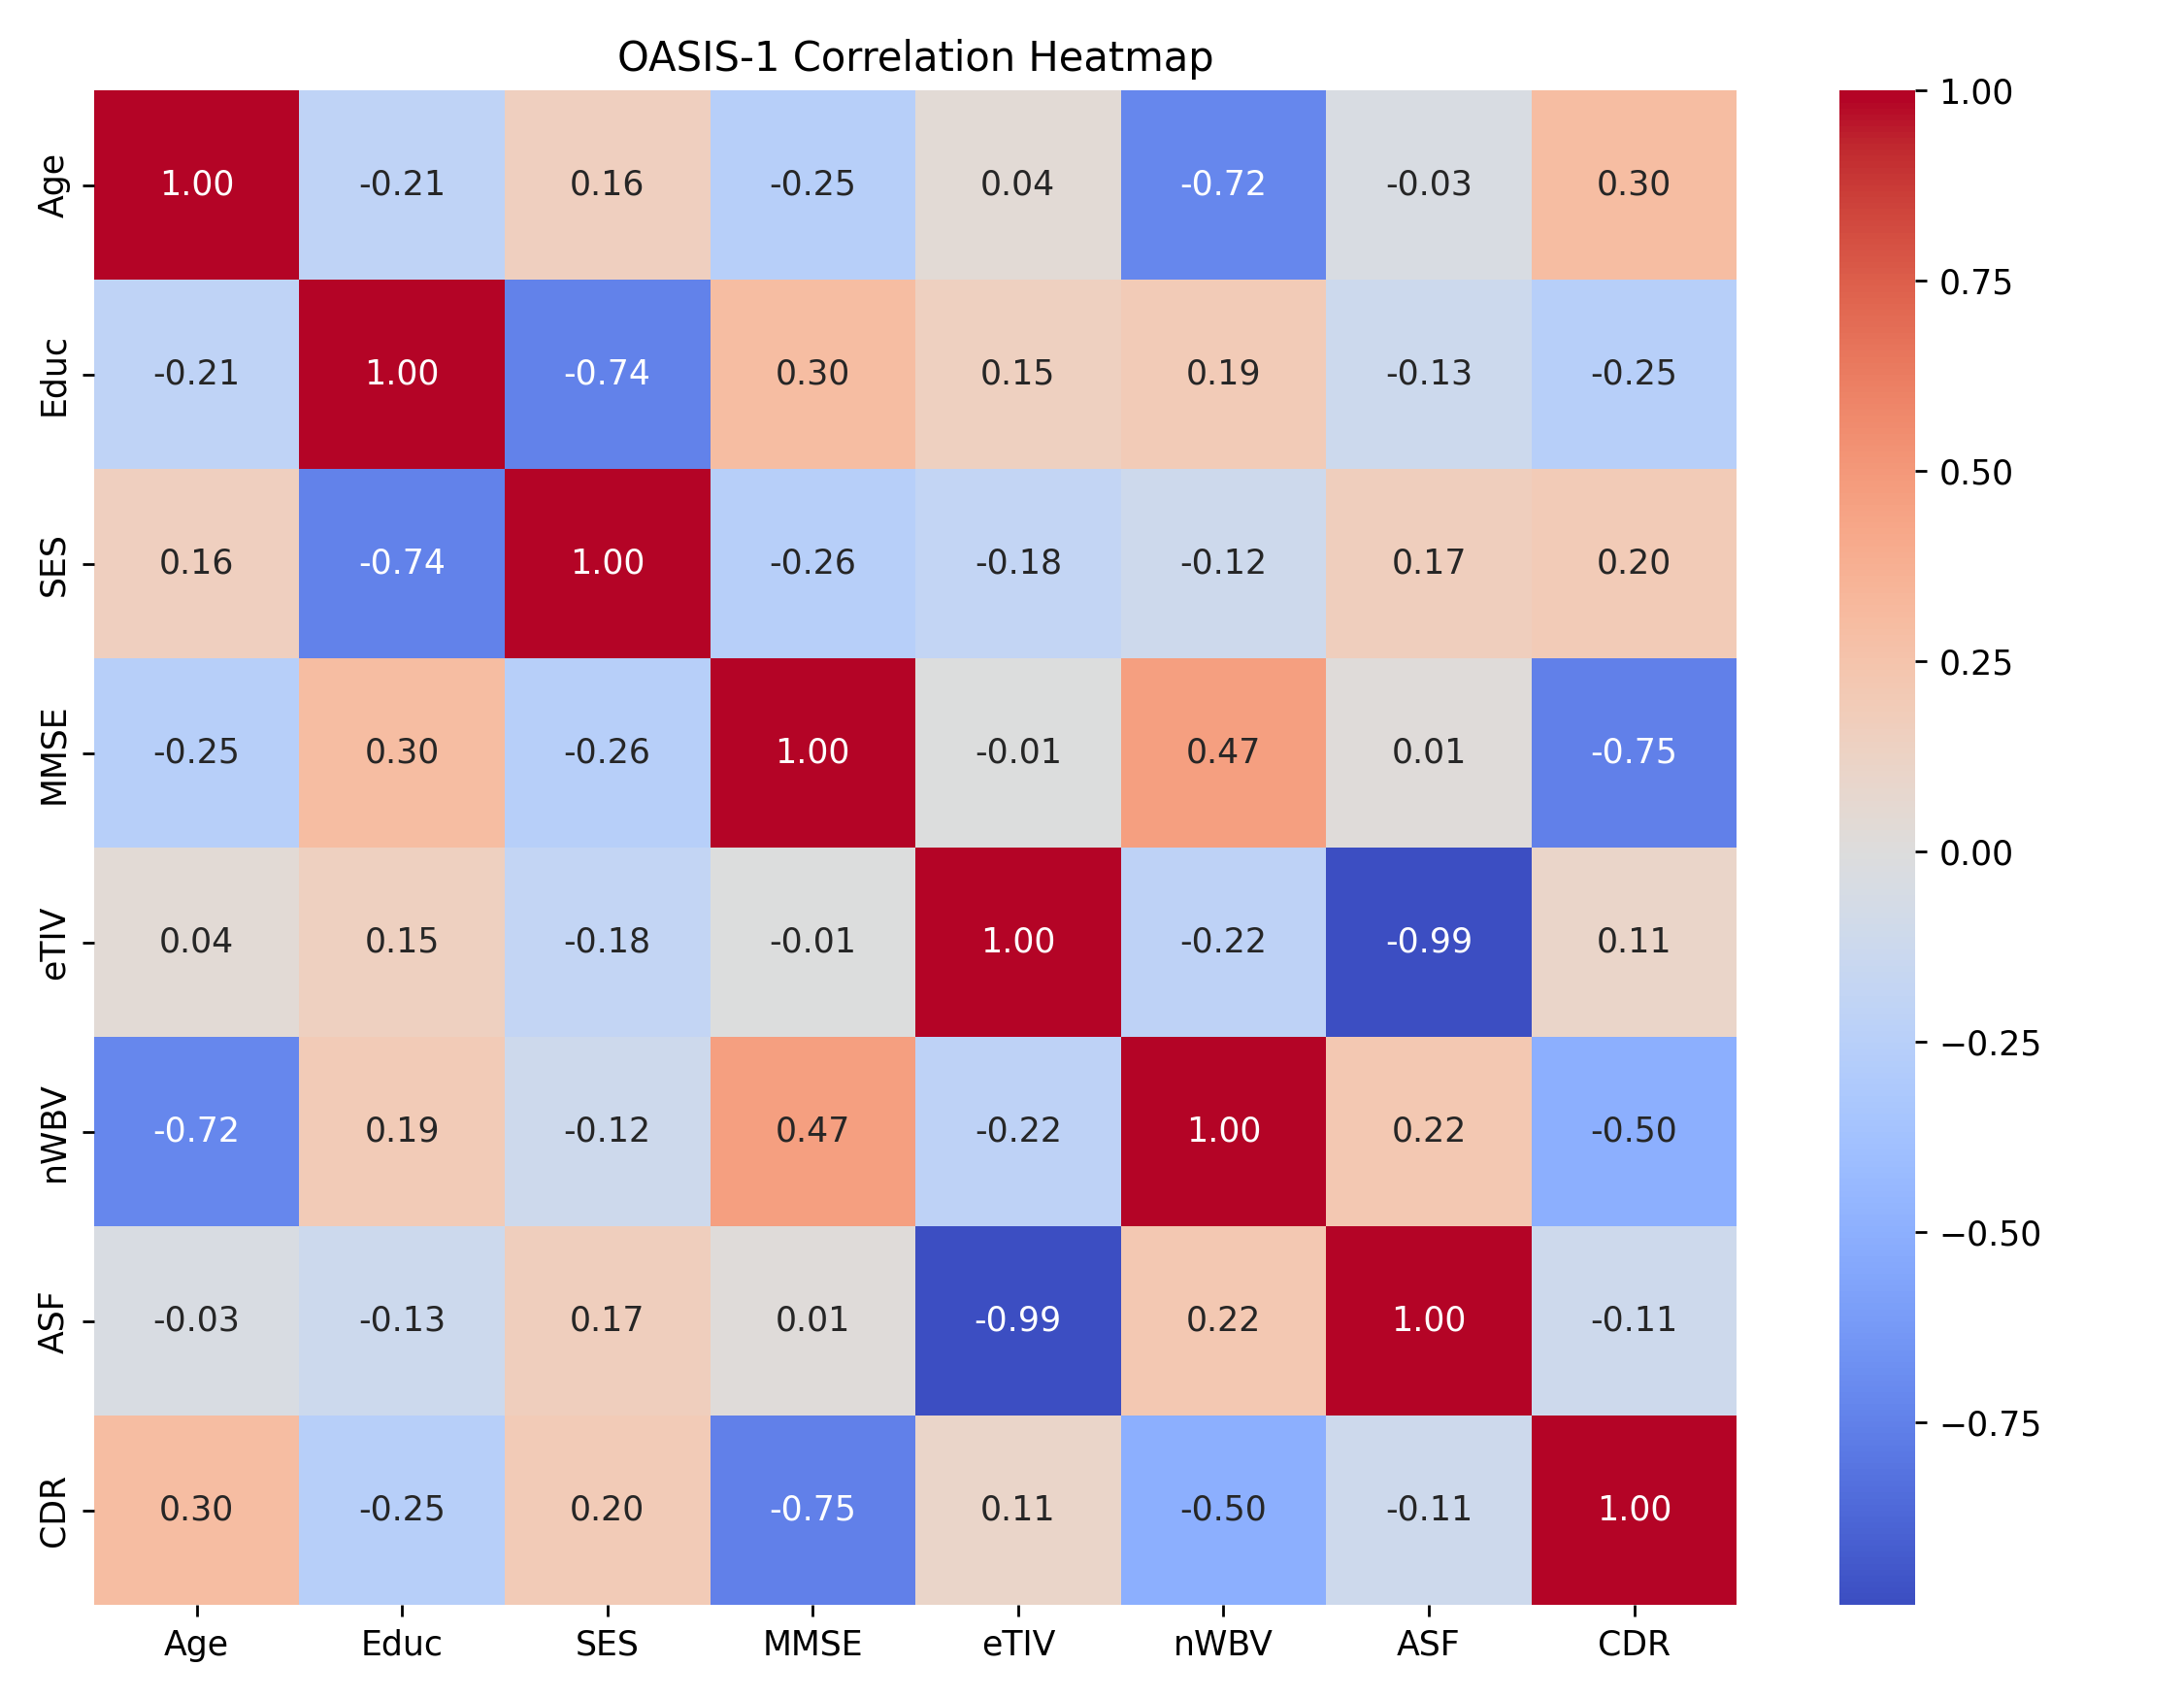

**Figure:** 08_shap_summary.png

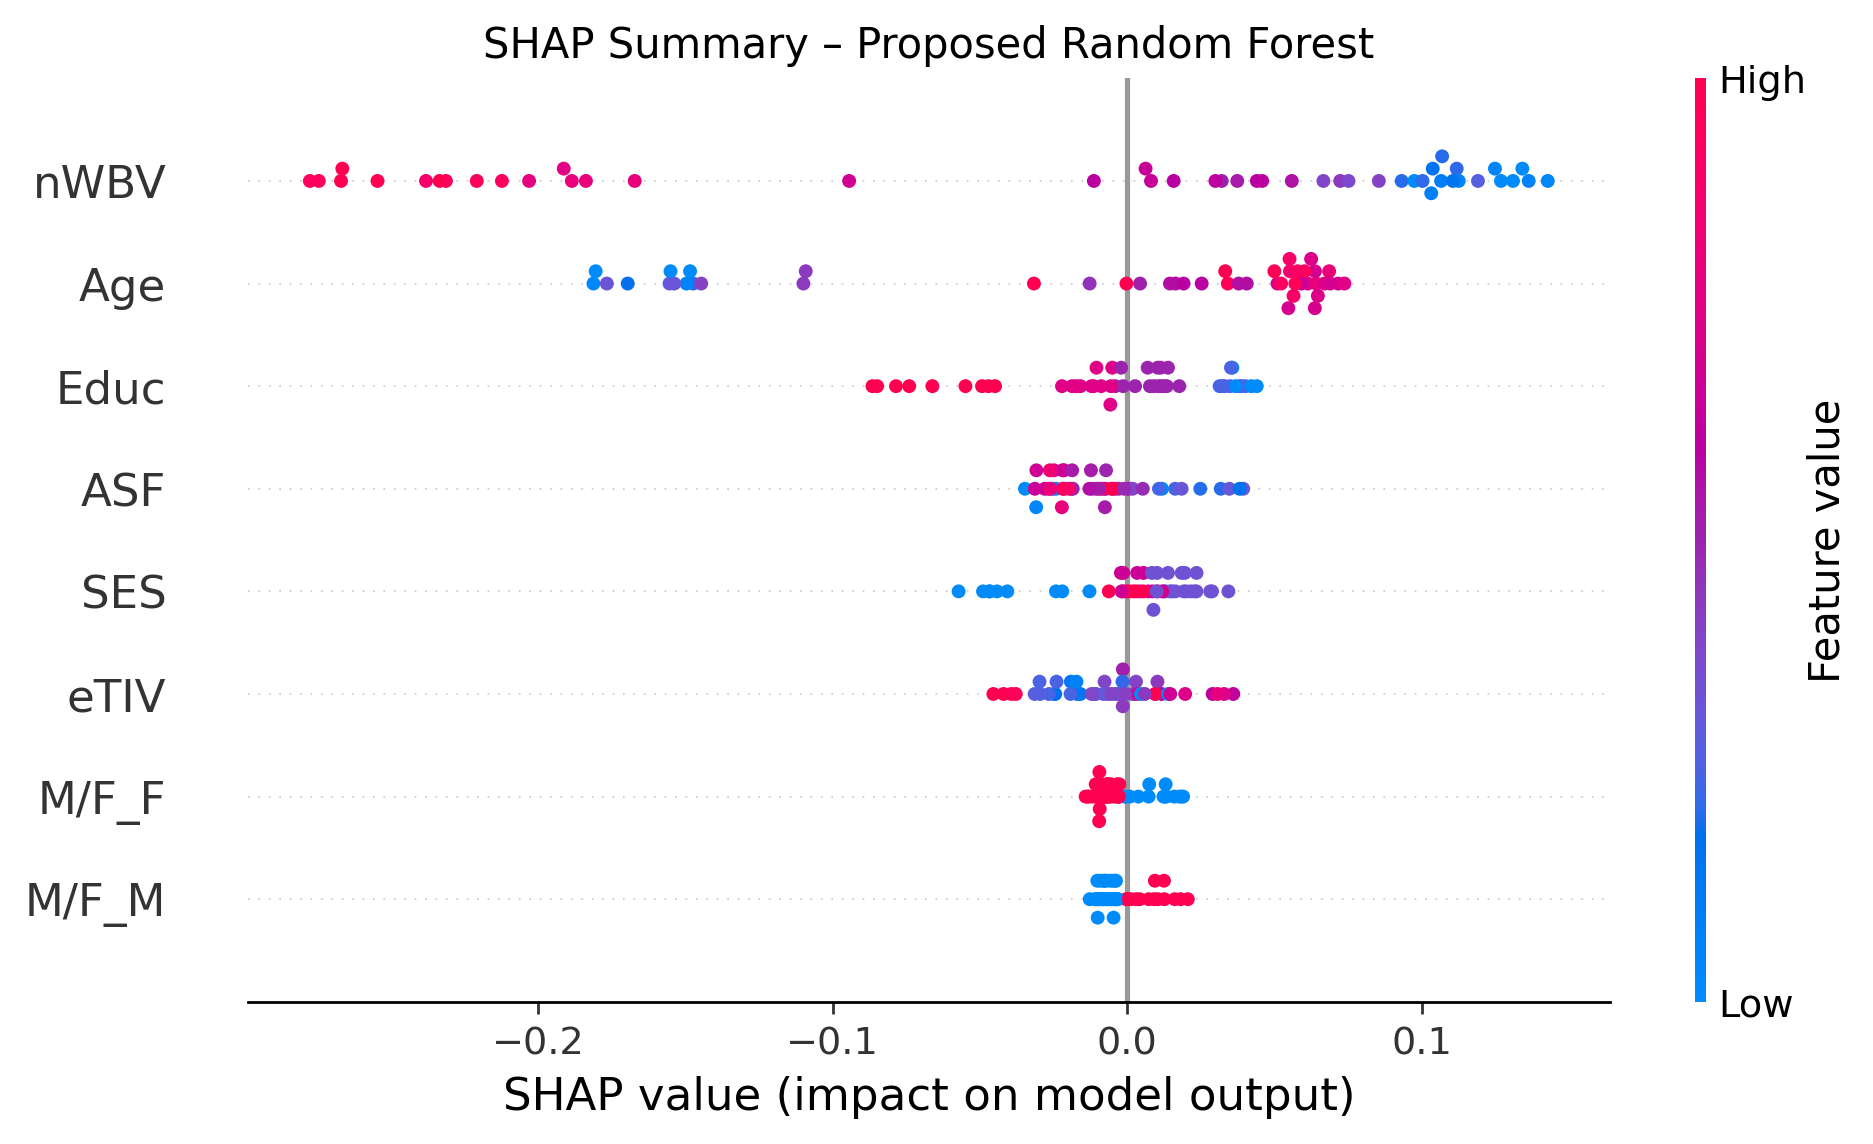

**Figure:** 01_class_distribution.png

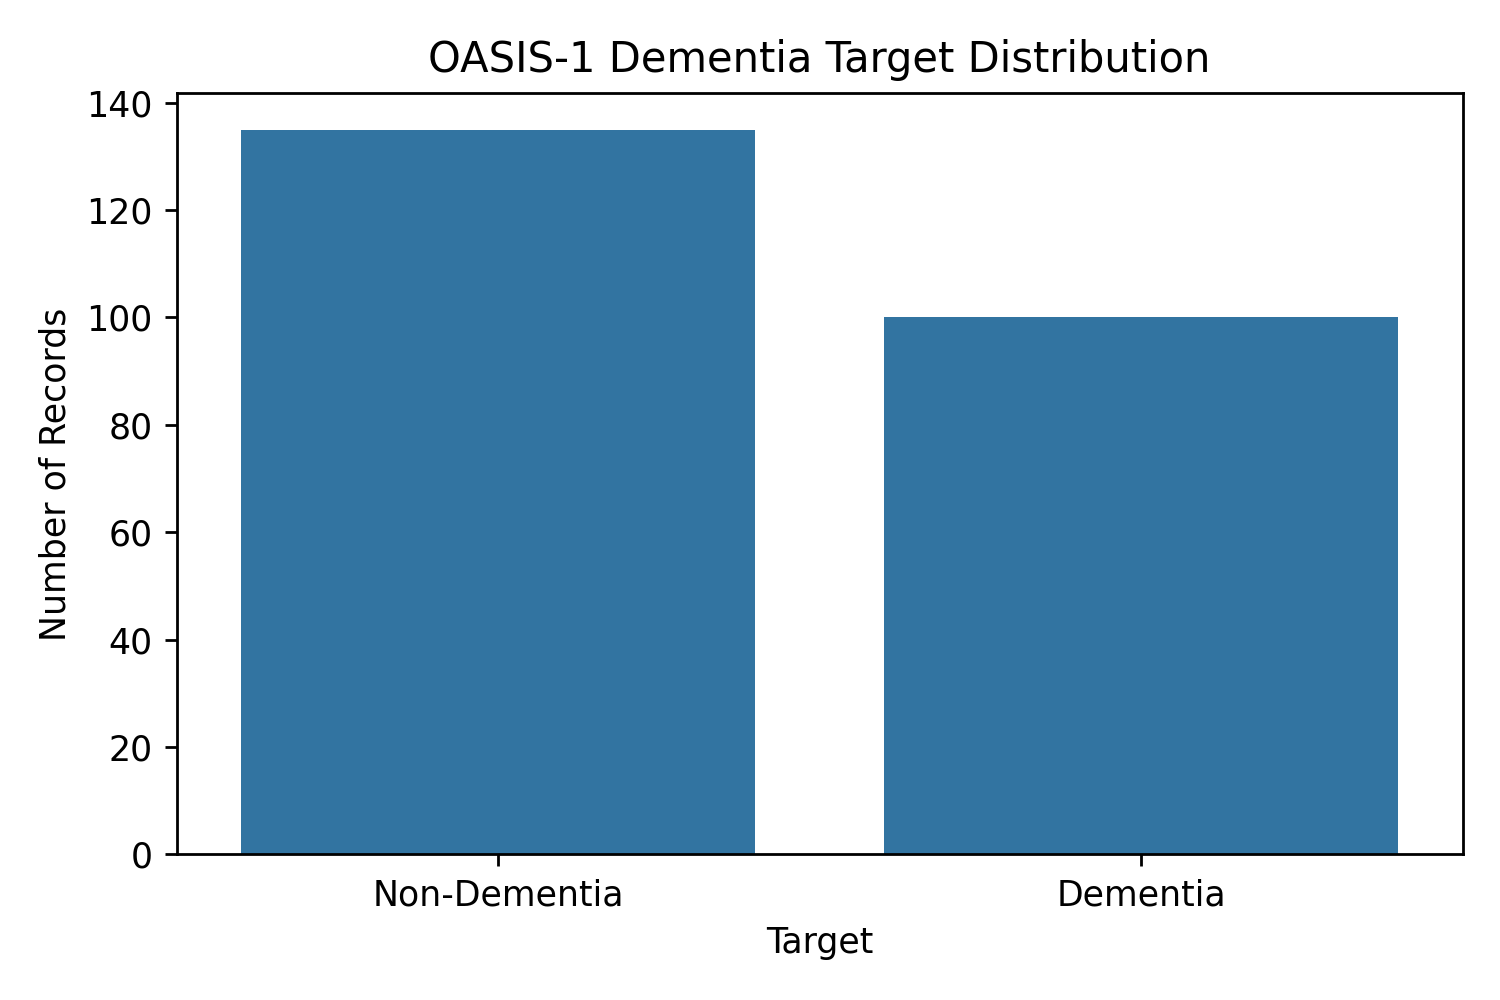

In [13]:
import pathlib
import pandas as pd
from IPython.display import display, Image, Markdown

# Define paths
results_dir = pathlib.Path('/content/results')
figures_dir = results_dir / 'figures'

# 1. Print the Run Summary
summary_file = results_dir / 'run_summary.txt'
if summary_file.exists():
    display(Markdown("### 📝 Project Execution Summary"))
    print(summary_file.read_text())

# 2. Display Model Comparison Table
comparison_file = results_dir / 'model_comparison.csv'
if comparison_file.exists():
    display(Markdown("### 📊 Model Comparison Metrics"))
    df_compare = pd.read_csv(comparison_file)
    display(df_compare)

# 3. Display Feature Importance Table
importance_file = results_dir / 'feature_importance.csv'
if importance_file.exists():
    display(Markdown("### 🔑 Feature Importance Metrics"))
    df_importance = pd.read_csv(importance_file)
    display(df_importance)

# 4. Display any generated figures
if figures_dir.exists():
    display(Markdown("### 🎨 Generated Figures & Plots"))
    for fig_path in figures_dir.glob('*.png'):
        display(Markdown(f"**Figure:** {fig_path.name}"))
        display(Image(filename=str(fig_path)))

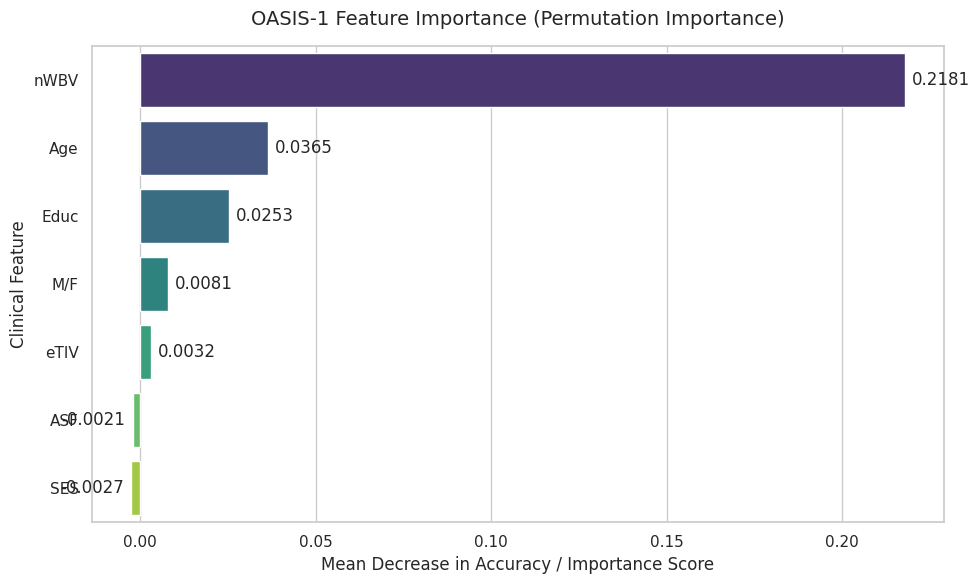

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure we have the feature importance data loaded
try:
    # Sort the dataframe to make the bar chart readable from highest to lowest
    df_importance_sorted = df_importance.sort_values(by='Importance', ascending=False)

    # Set up the visualization style
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="whitegrid")

    # Create the horizontal bar plot
    ax = sns.barplot(
        x='Importance',
        y='Feature',
        data=df_importance_sorted,
        palette='viridis',
        hue='Feature',
        legend=False
    )

    # Add values on the bar charts
    for container in ax.containers:
        ax.bar_label(container, fmt='%.4f', padding=5)

    plt.title("OASIS-1 Feature Importance (Permutation Importance)", fontsize=14, pad=15)
    plt.xlabel("Mean Decrease in Accuracy / Importance Score", fontsize=12)
    plt.ylabel("Clinical Feature", fontsize=12)
    plt.tight_layout()
    plt.show()
except NameError:
    print("Feature importance data 'df_importance' not found in kernel state. Please make sure the previous cell ran successfully.")

### 🎨 Displaying All 8 Generated Figures

#### **Figure:** 01_class_distribution.png

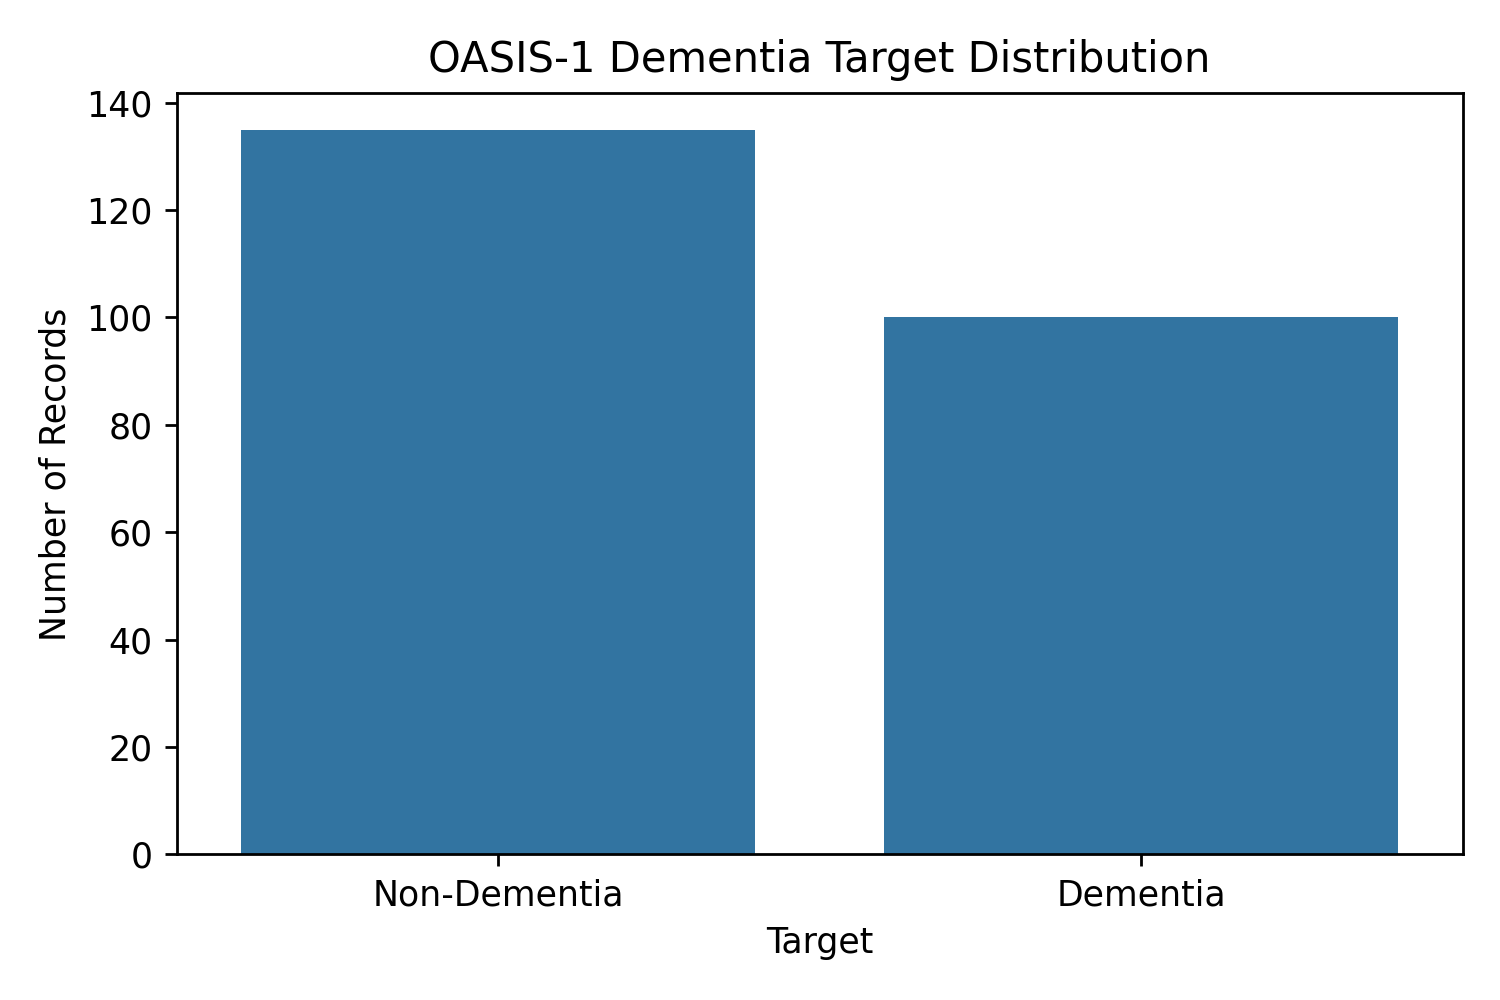

#### **Figure:** 02_correlation_heatmap.png

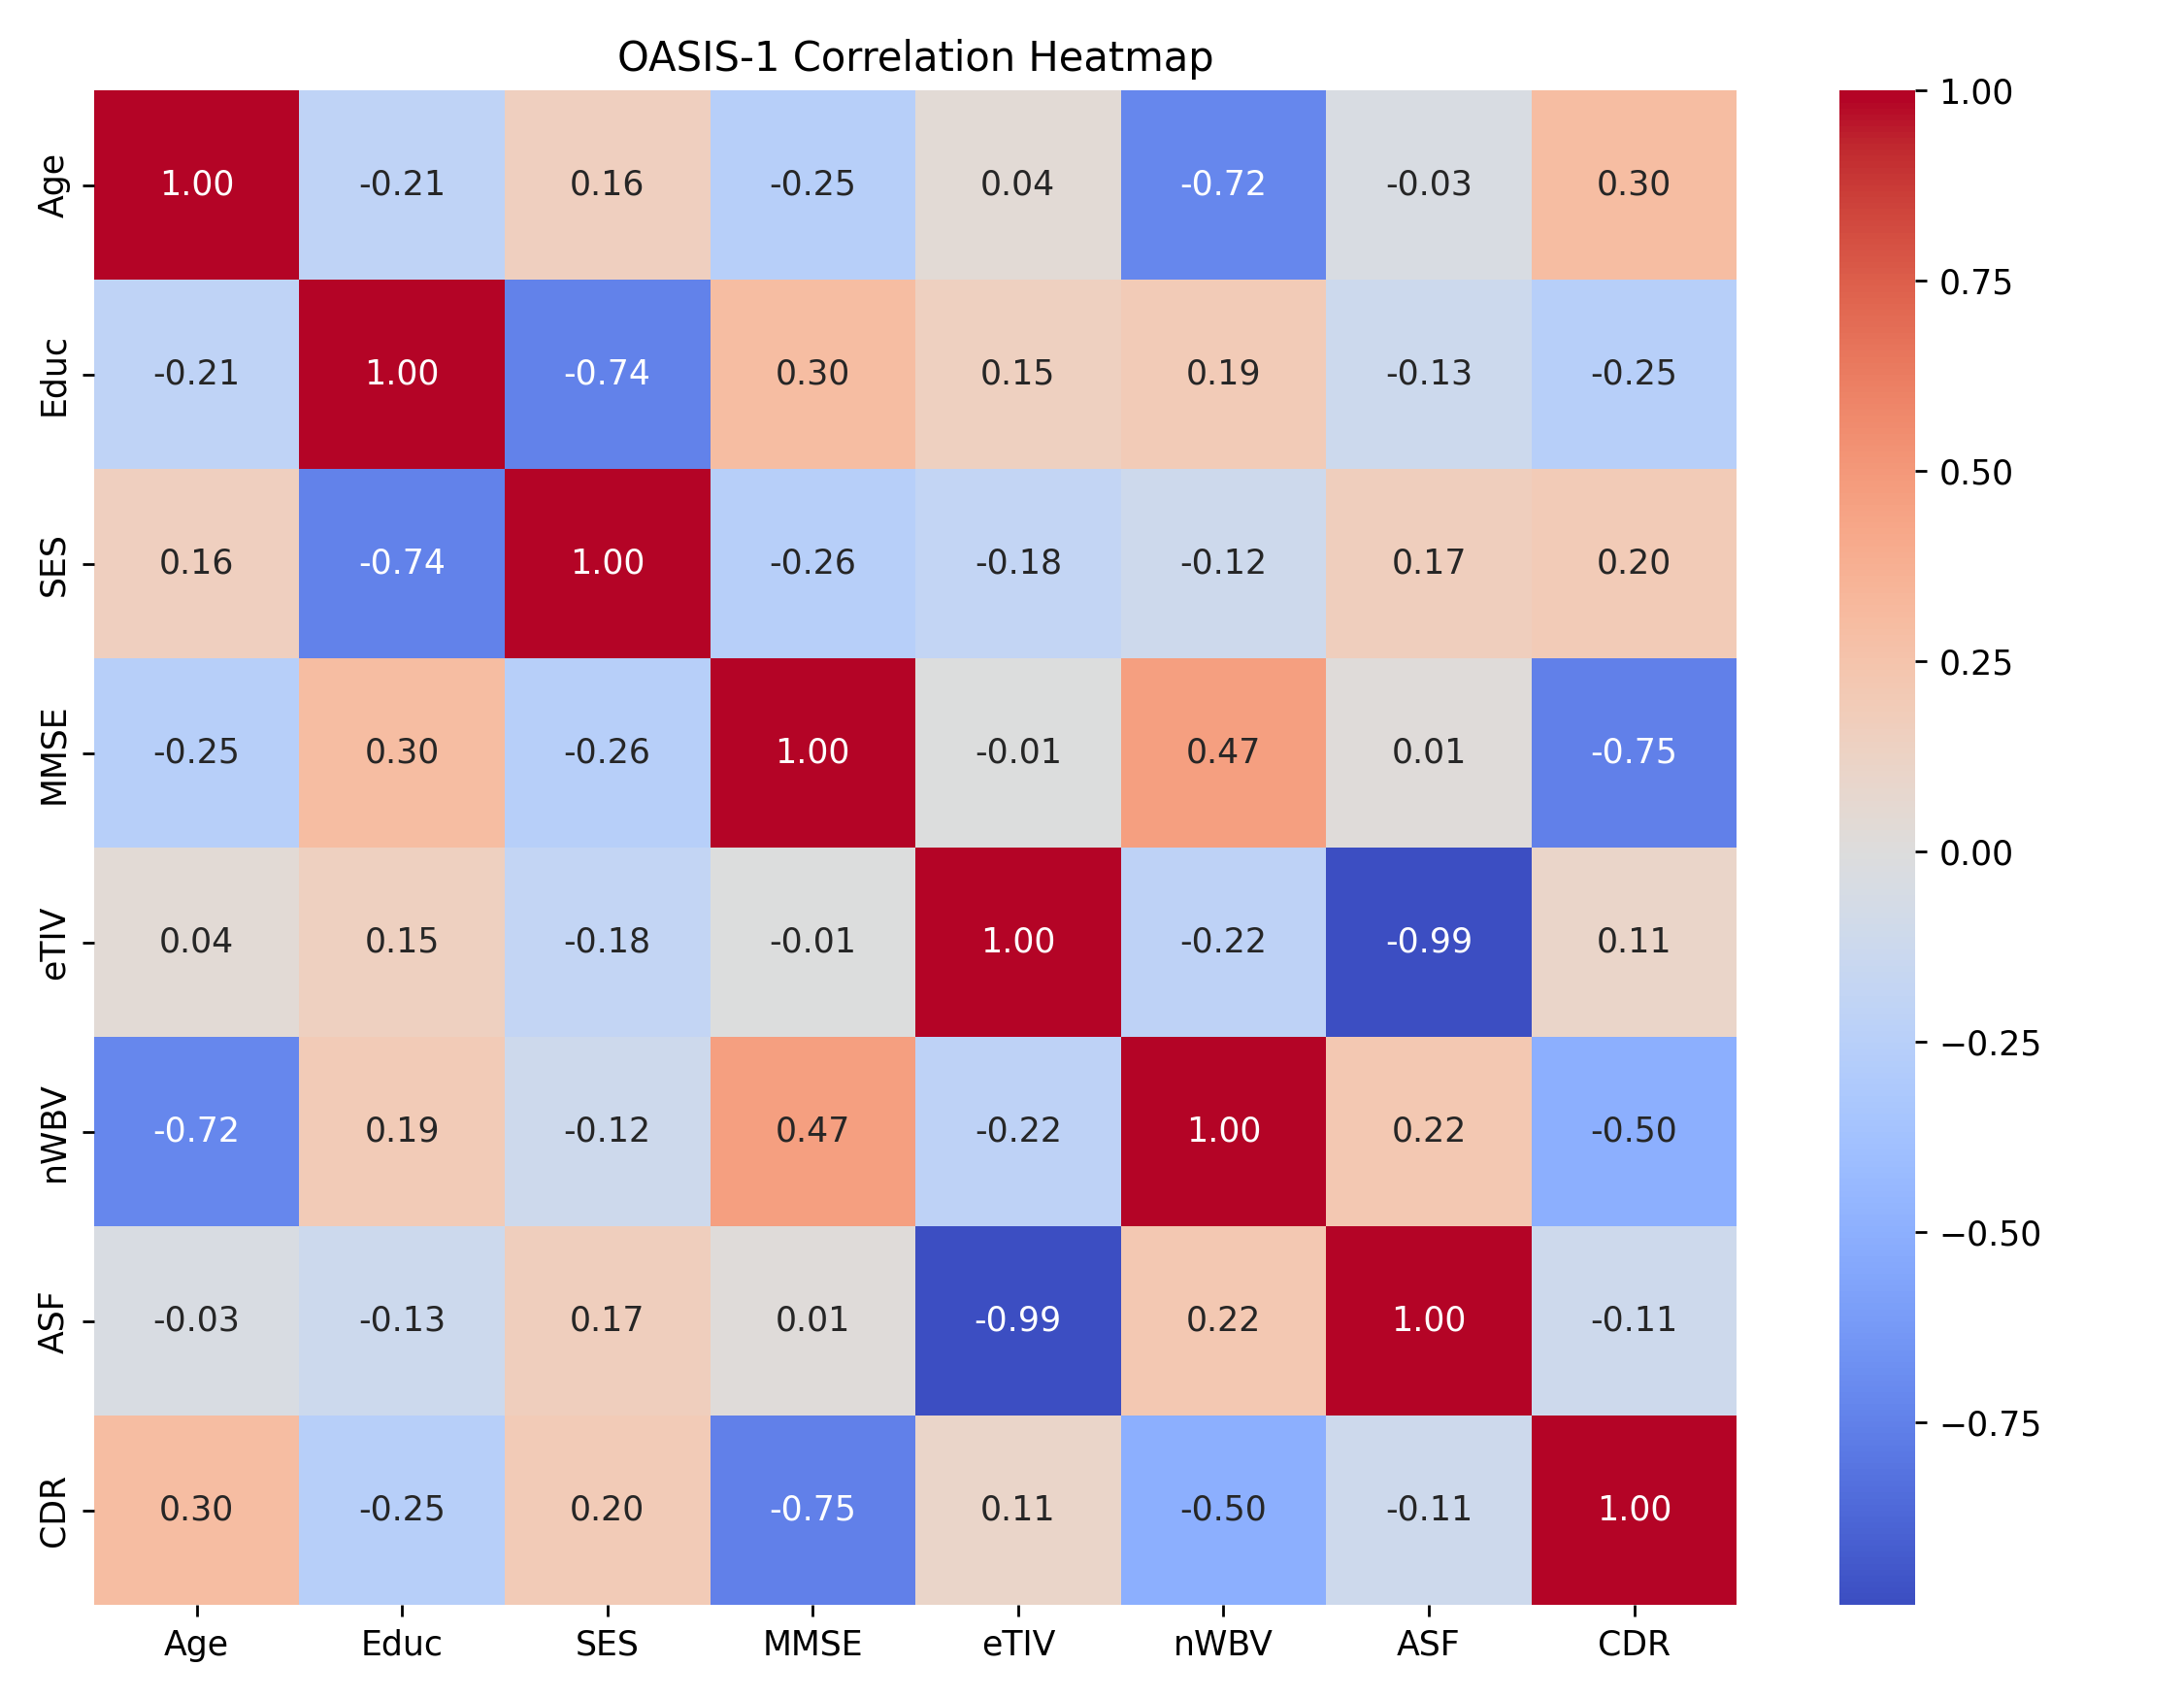

#### **Figure:** 03_age_vs_nwbv.png

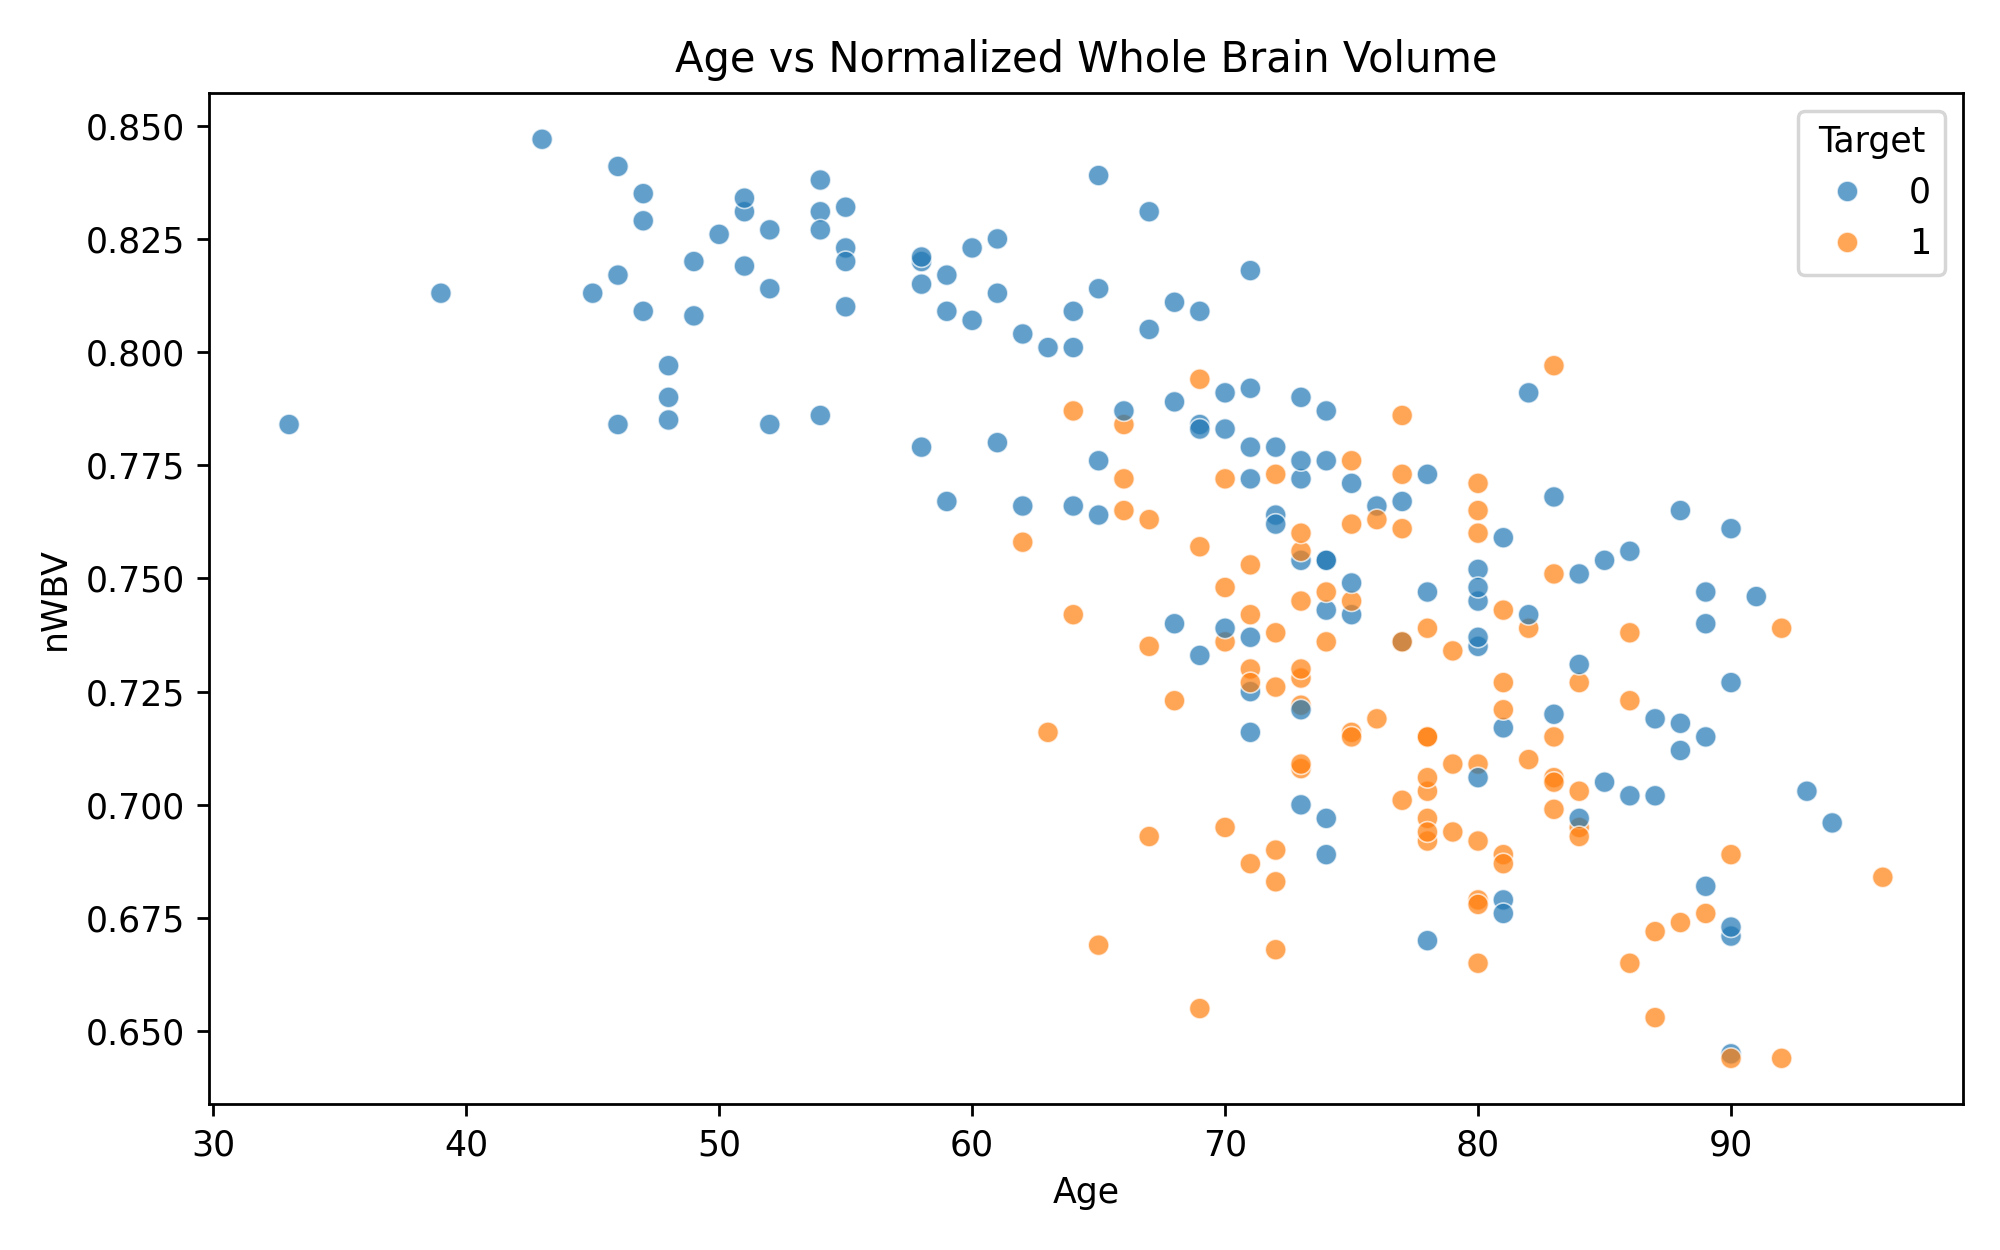

#### **Figure:** 04_threshold_optimization.png

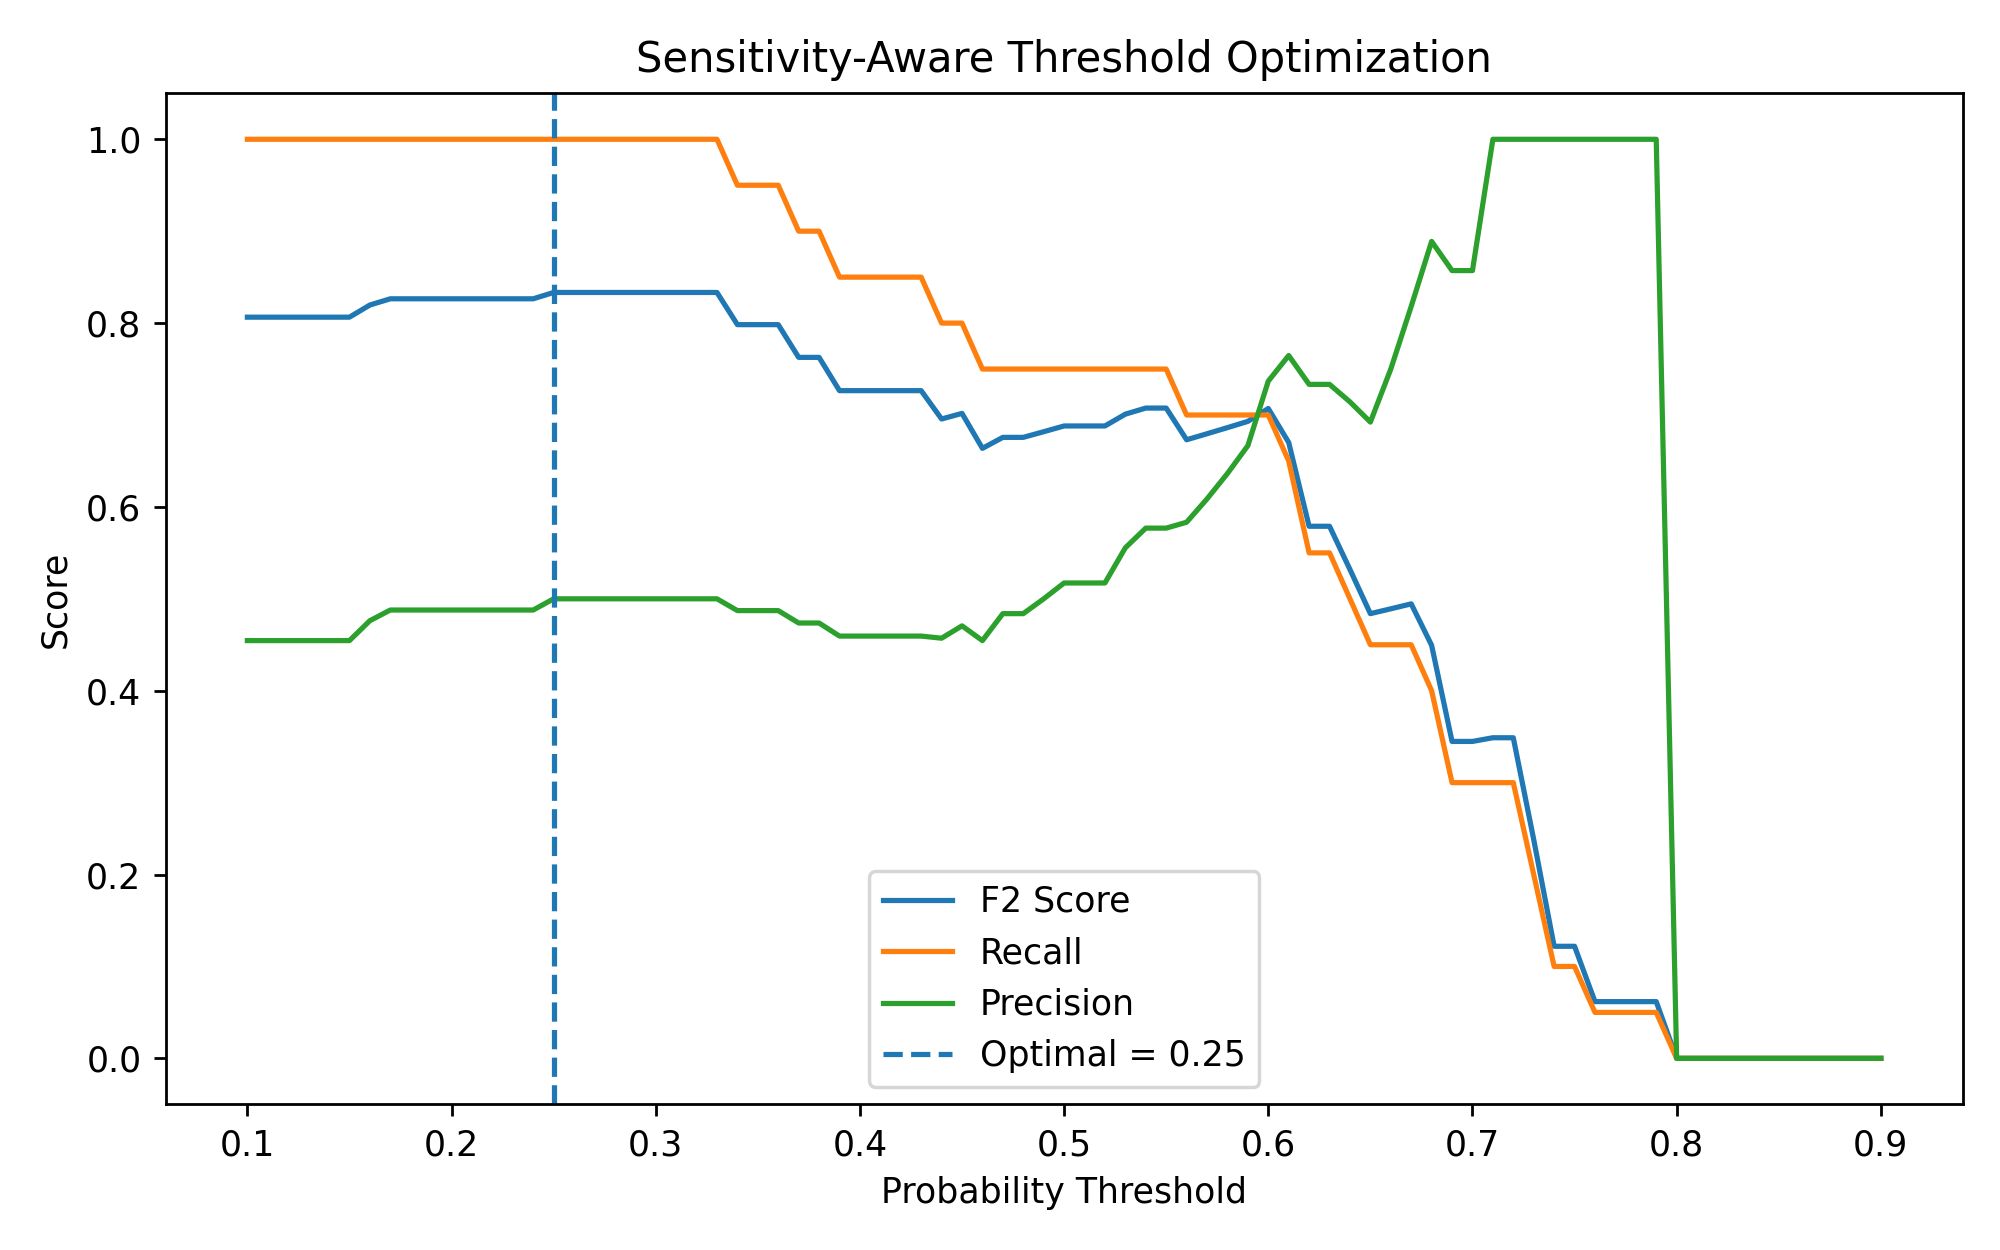

#### **Figure:** 05_confusion_matrix.png

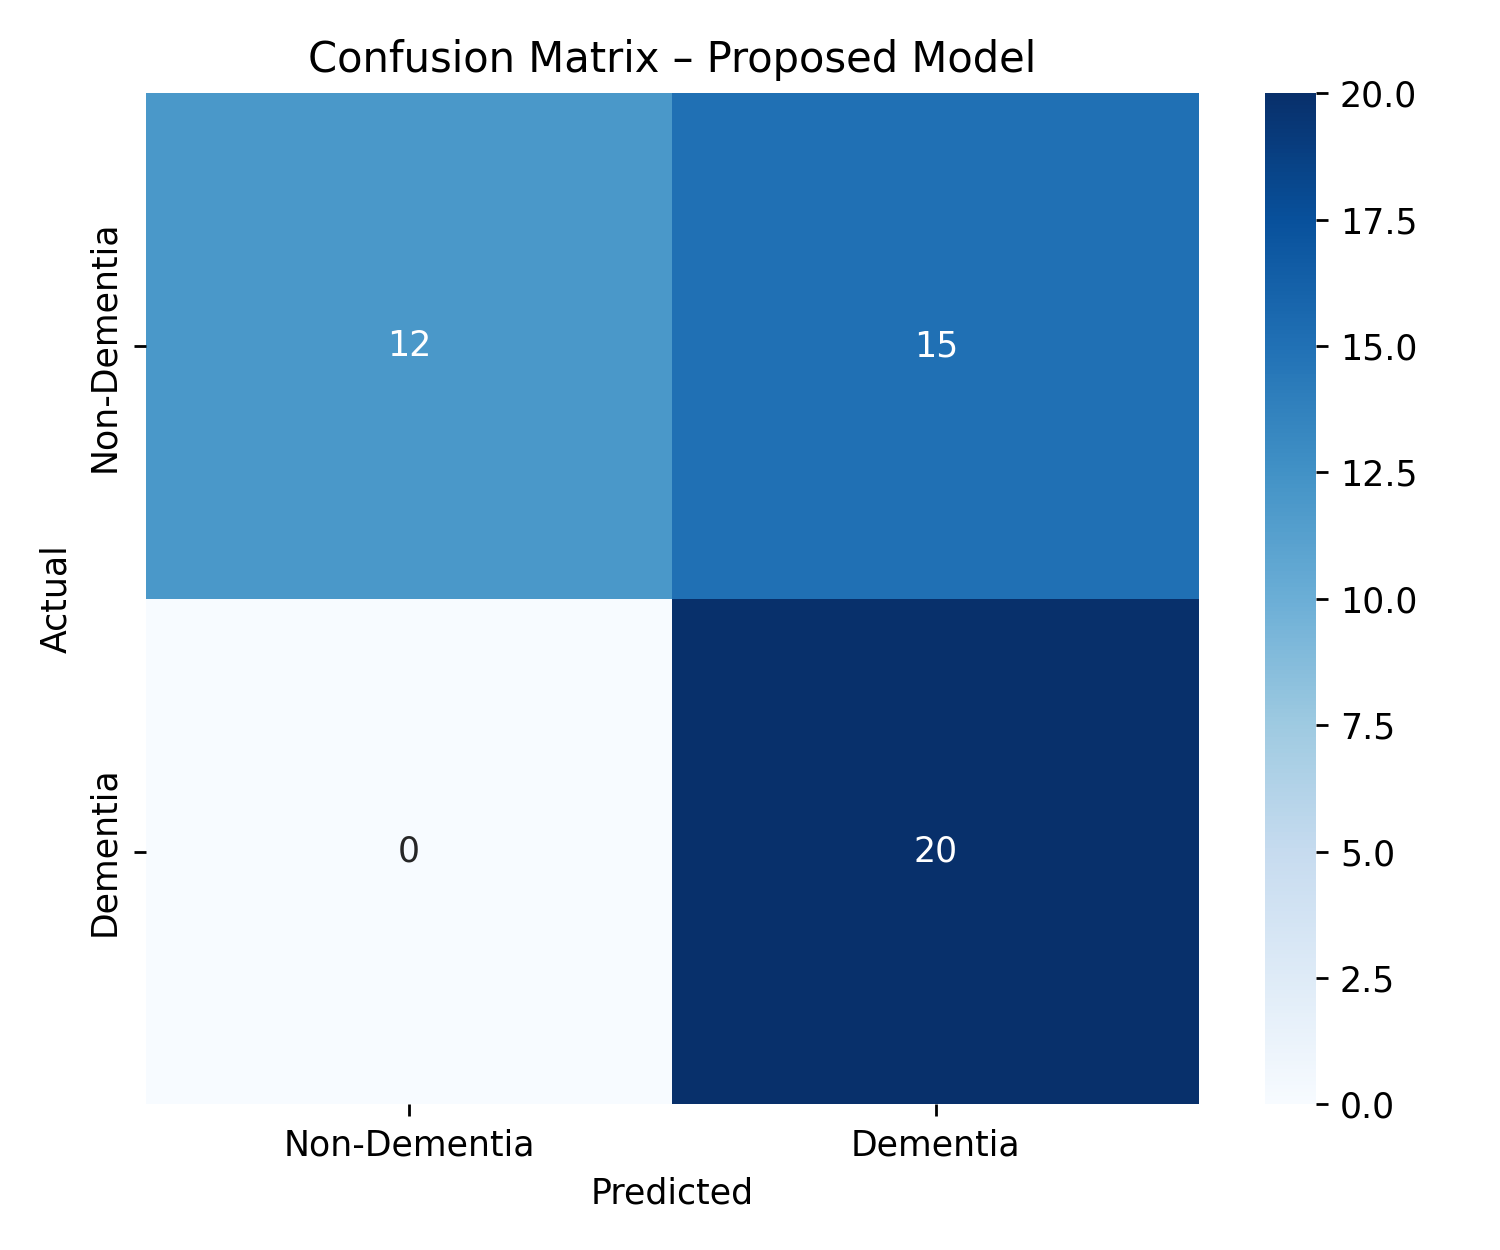

#### **Figure:** 06_roc_comparison.png

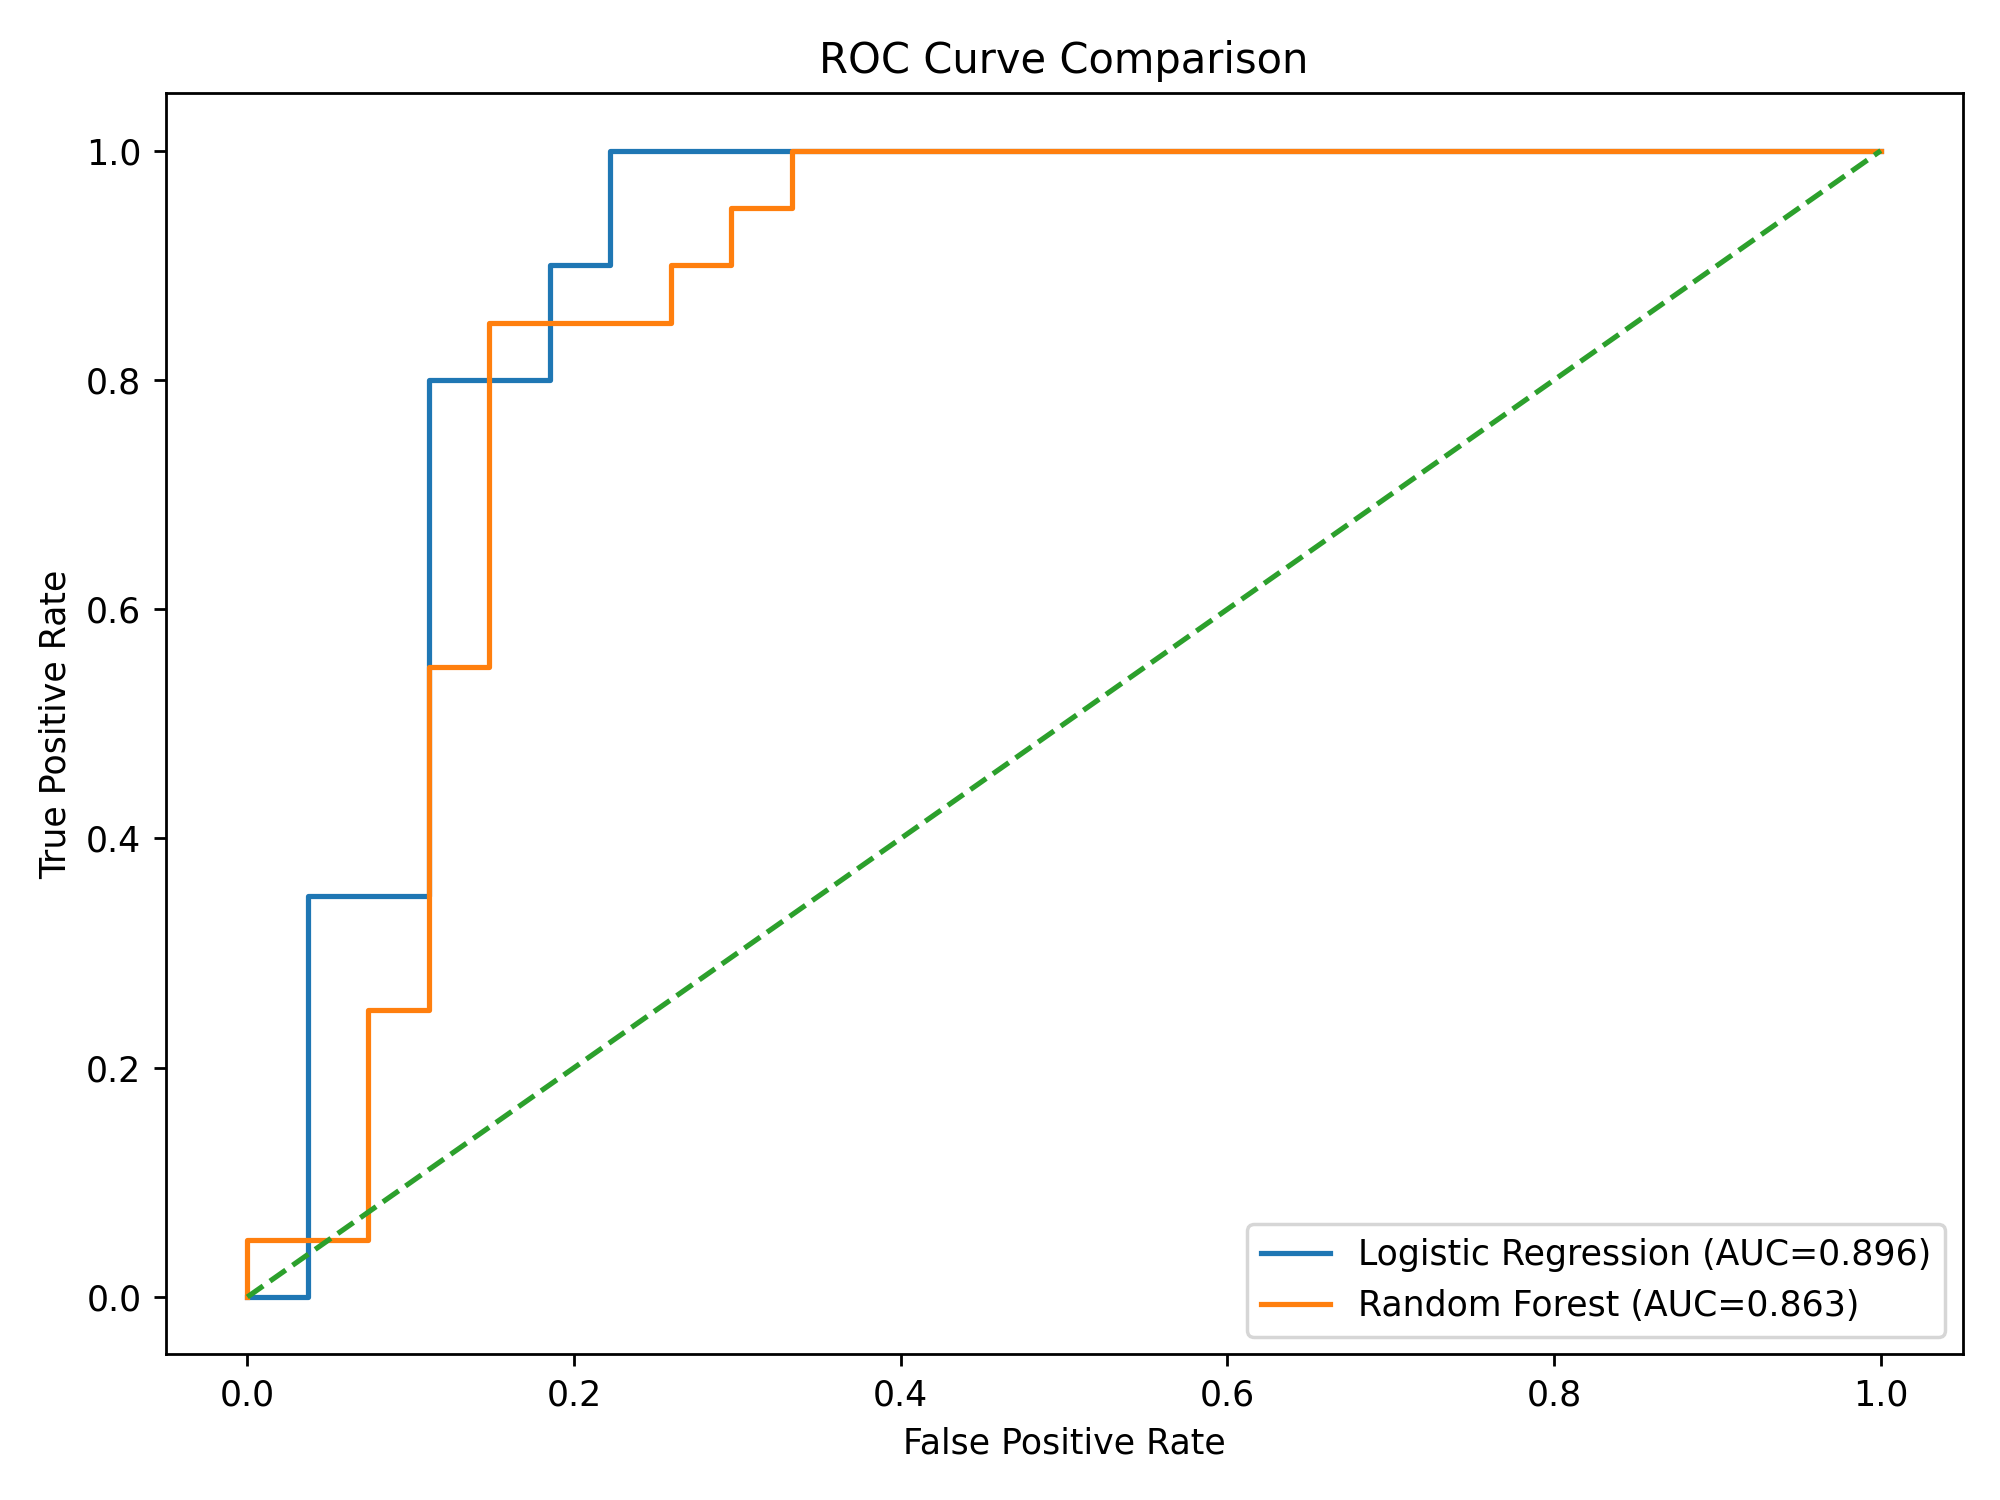

#### **Figure:** 07_feature_importance.png

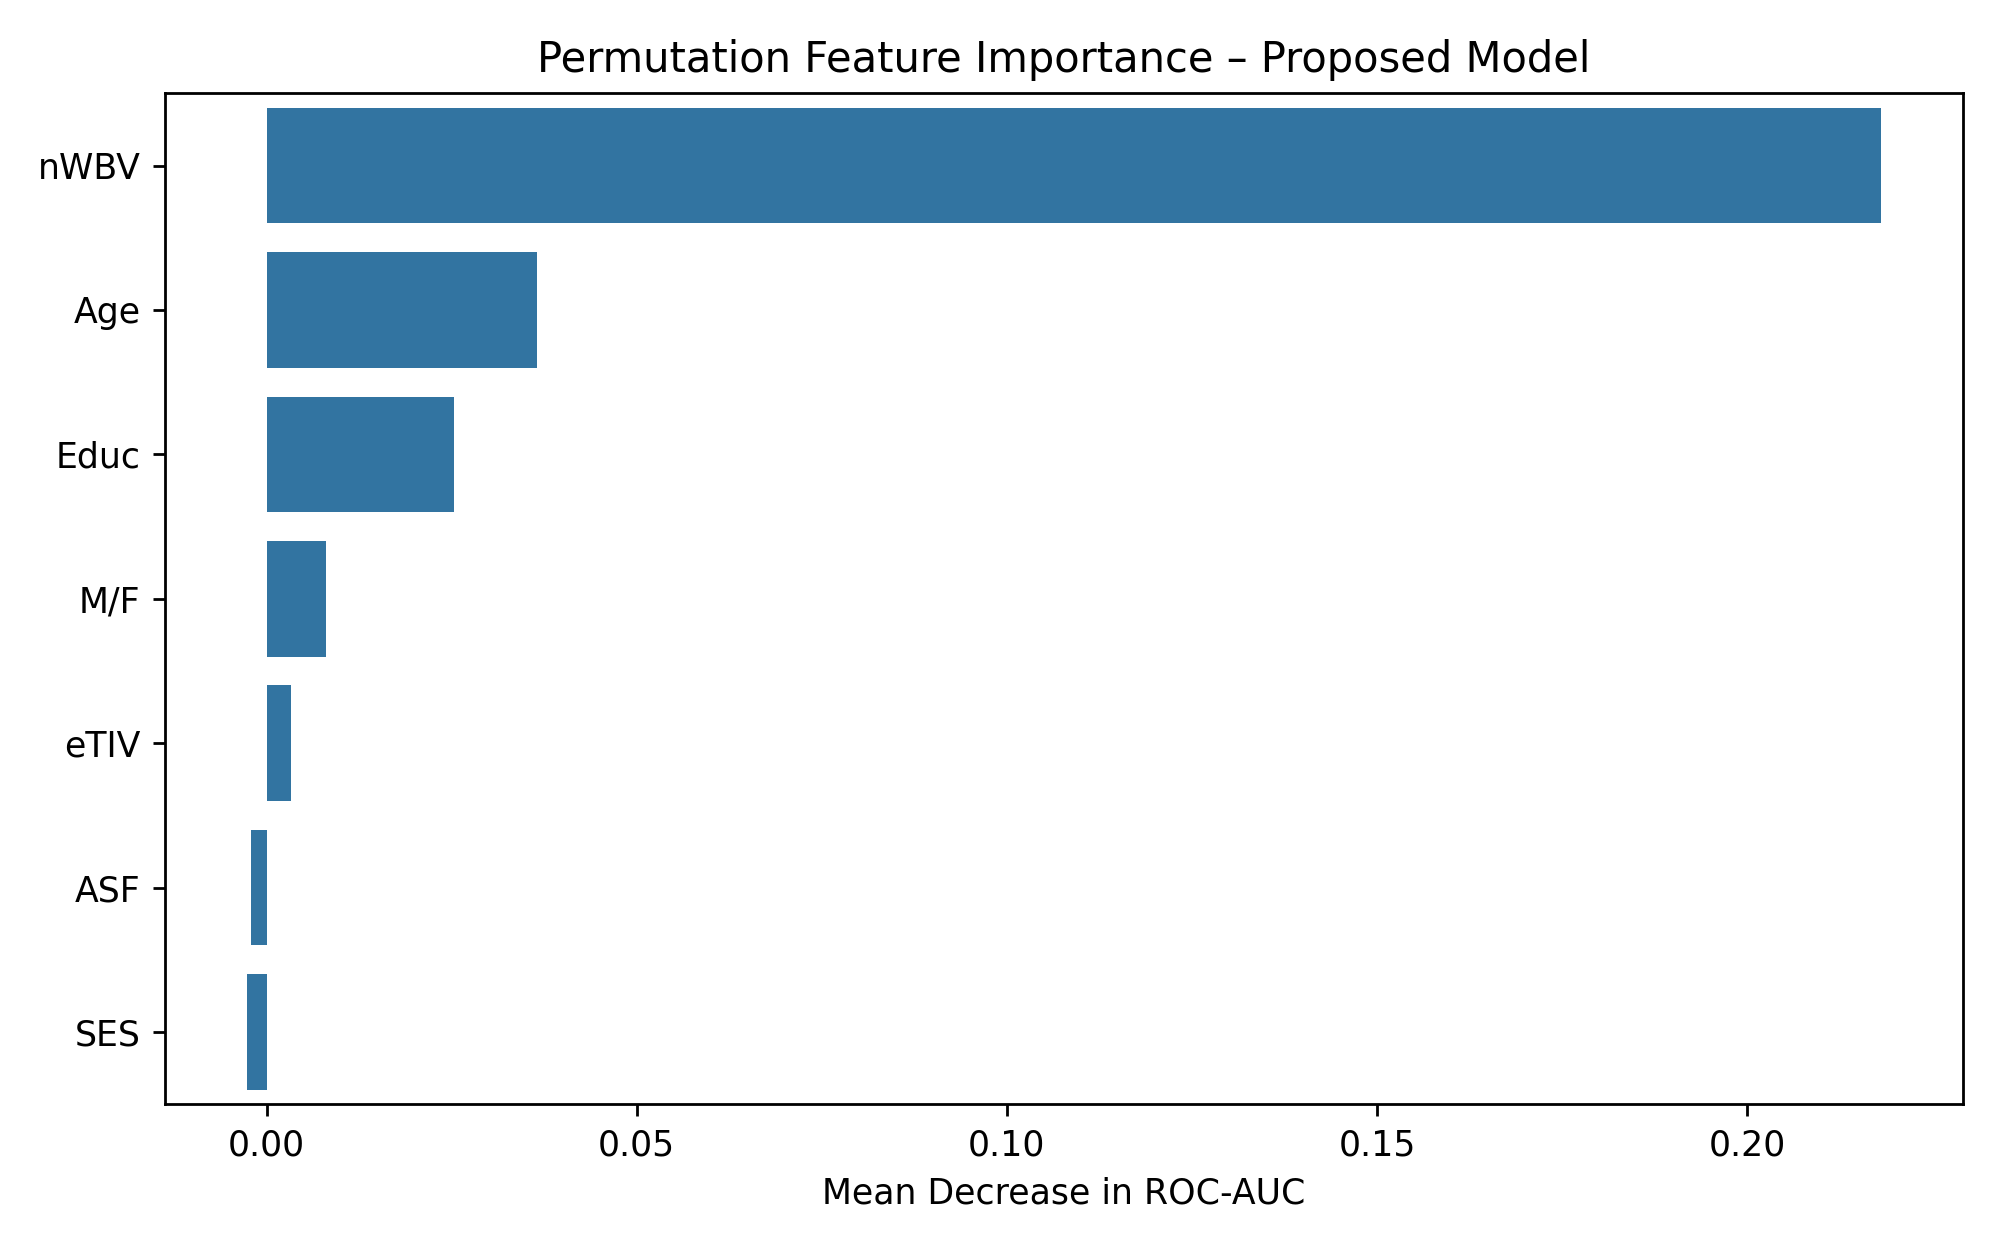

#### **Figure:** 08_shap_summary.png

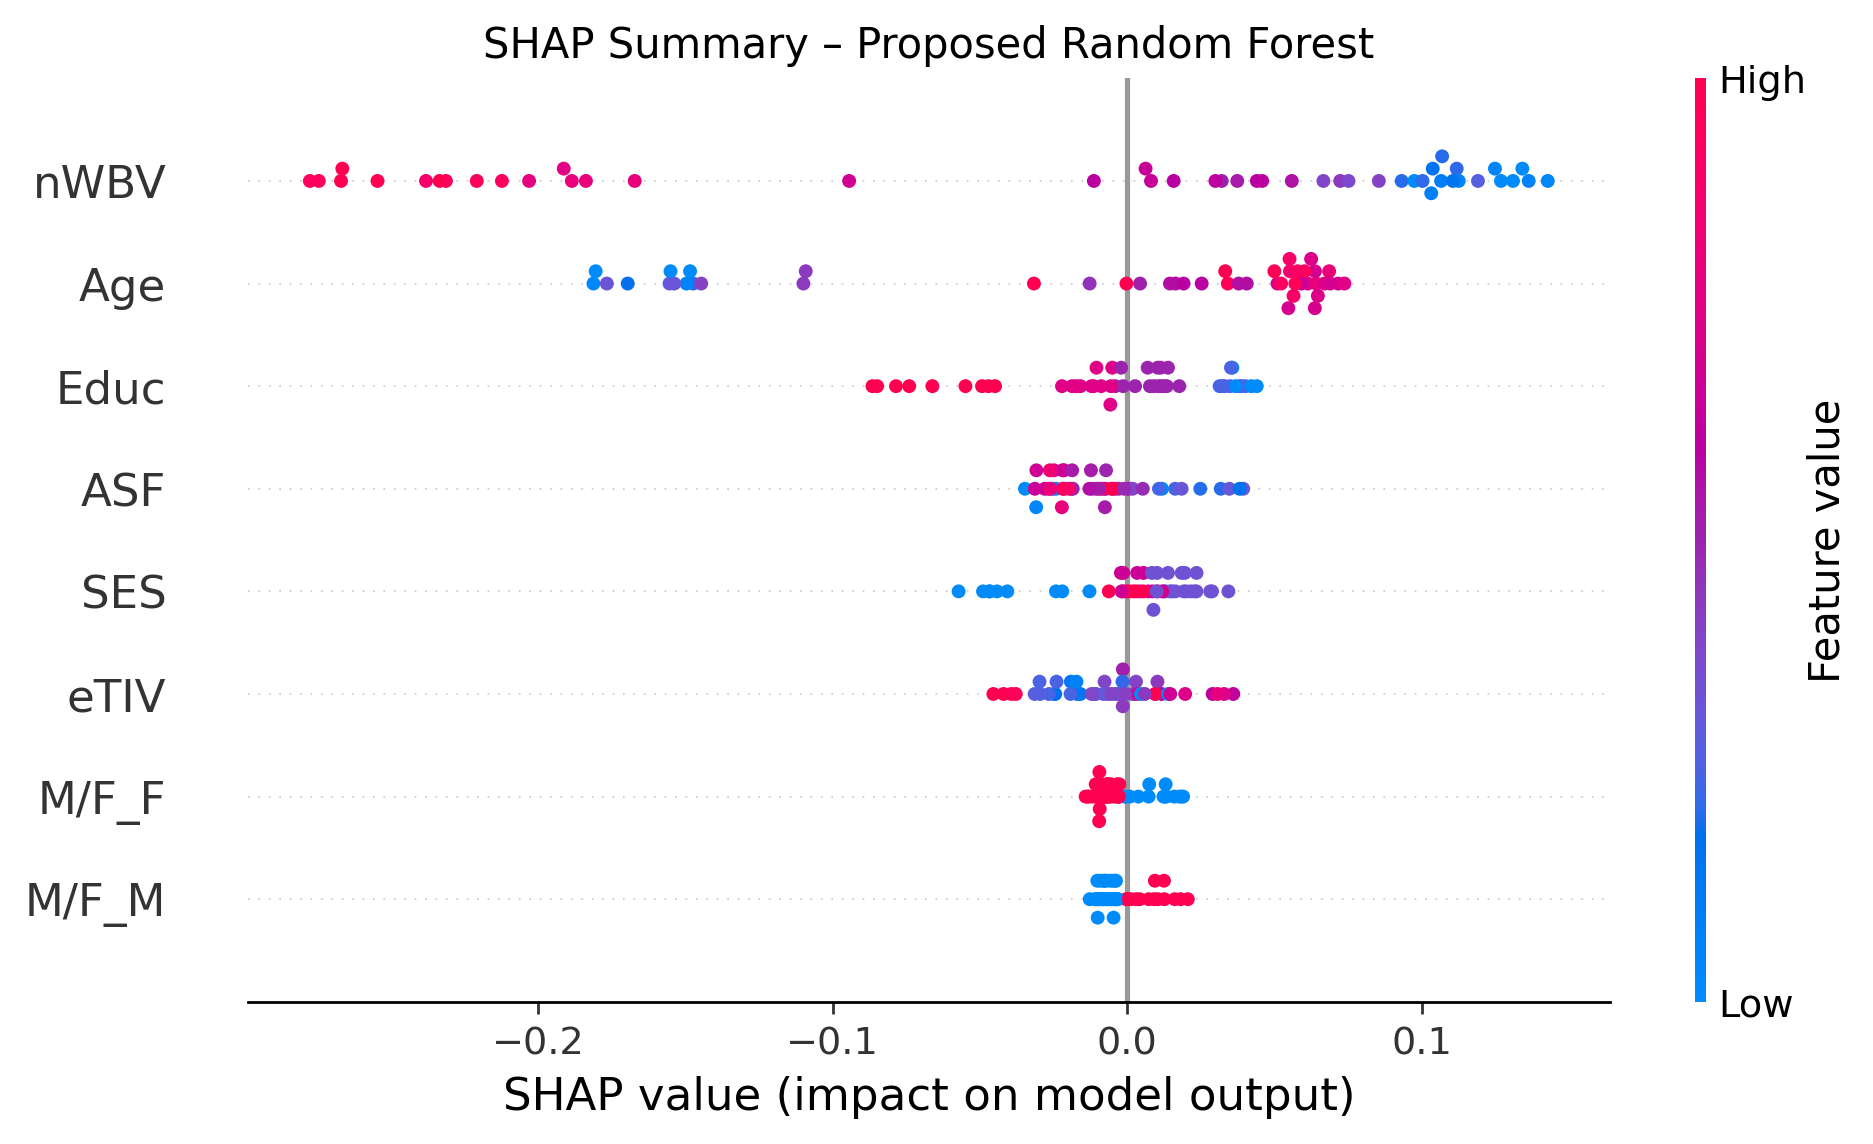

In [15]:
import pathlib
from IPython.display import display, Image, Markdown

figures_dir = pathlib.Path('/content/results/figures')
if figures_dir.exists():
    figures = sorted(list(figures_dir.glob('*.png')))
    if figures:
        display(Markdown(f"### 🎨 Displaying All {len(figures)} Generated Figures"))
        for fig_path in figures:
            display(Markdown(f"#### **Figure:** {fig_path.name}"))
            display(Image(filename=str(fig_path)))
    else:
        print("No image figures found in the directory.")
else:
    print("Figures directory does not exist.")

In [16]:
import shutil
from google.colab import files

# Compress the results directory into a zip file
shutil.make_archive('/content/oasis_project_results', 'zip', '/content/results')

# Trigger the download to the local machine
files.download('/content/oasis_project_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 💾 Save notebook as a copy

To save a copy of this notebook for future reference, you can use either of the options below:

* **Option 1 (Colab Menu)**: Click on **File** > **Save a copy in Drive** in the top menu.
* **Option 2 (Local Download)**: Run the cell below to programmatically fetch, backup, and download the current notebook file (`.ipynb`) directly to your machine.

In [18]:
import os
from google.colab import files

# Look for any .ipynb files in the Colab runtimes configurations
ipynb_files = [f for f in os.listdir('.') if f.endswith('.ipynb')]

if ipynb_files:
    for file in ipynb_files:
        print(f"Downloading notebook: {file}")
        files.download(file)
else:
    # fallback instruction if running unnamed
    print("To manually save a copy, please go to the menu: File -> Download -> Download .ipynb")

To manually save a copy, please go to the menu: File -> Download -> Download .ipynb


In [ ]:
import json
from google.colab import files

try:
    # Use Colab's internal API to download the active notebook file with all code and outputs intact
    from google.colab import _message
    notebook_json = _message.blocking_request('get_ipynb', request='', timeout_sec=10)

    with open('/content/oasis_complete_notebook.ipynb', 'w', encoding='utf-8') as f:
        json.dump(notebook_json['ipynb'], f, indent=2)

    print("✓ Successfully compiled code and outputs into a single file!")
    files.download('/content/oasis_complete_notebook.ipynb')
except Exception as e:
    print("Could not automatically fetch the active notebook file via code.")
    print("\nAlternative manual step to get your single file containing both code and output:")
    print("Go to the top left menu: File -> Download -> Download .ipynb")

### 🖨️ PDF Print Optimization Layout

Run the cell below to inject custom print CSS. This stylesheet tells your browser's PDF generator how to handle element sizing, page boundaries, and prevents blank/clipping pages.

In [19]:
from IPython.display import HTML

# Injecting print CSS rules to clean up page breaks and shrink oversized charts for standard PDF printing
HTML('''
<style>
@media print {
    /* Prevent blank page starts and isolate page break behaviors */
    .cell, .output_wrapper, .output, .output_area, img {
        page-break-inside: avoid !important;
    }

    /* Maximize image layouts to fit on a single standard page */
    img {
        max-width: 100% !important;
        max-height: 85vh !important;
        object-fit: contain !important;
    }

    /* Hide interactive sidebar components and prompt margins */
    .prompt, .colab-output-actions, .output_subarea.output_text pre {
        border: none !important;
    }
}
</style>
<div style="color: green; font-weight: bold;">✓ PDF Print Layout Optimization Successfully Applied! You can now use your browser's print option (Ctrl+P / Cmd+P) safely.</div>
''')

### 📄 Standalone Export Tool for Flawless PDF Printing

Run this cell to package your complete notebook, its metrics, and all 8 generated figures into a beautifully formatted, standalone file. This bypasses Colab's layout constraints entirely to guarantee zero blank pages!

In [20]:
import os
from IPython.display import HTML, display
from google.colab import files

# Create a highly polished, clean HTML template to host the report
html_content = """
<!DOCTYPE html>
<html>
<head>
<meta charset="utf-8">
<title>OASIS-1 Alzheimer's ML Project Report</title>
<style>
    body { font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; line-height: 1.6; color: #333; margin: 40px auto; max-width: 900px; padding: 0 20px; }
    h1 { border-bottom: 2px solid #333; padding-bottom: 10px; color: #1a365d; }
    h2 { color: #2b6cb0; margin-top: 30px; border-bottom: 1px solid #e2e8f0; padding-bottom: 5px; }
    h3 { color: #4a5568; }
    table { width: 100%; border-collapse: collapse; margin: 20px 0; }
    th, td { border: 1px solid #cbd5e0; padding: 10px; text-align: left; }
    th { background-color: #f7fafc; }
    .figure-container { margin: 30px 0; text-align: center; page-break-inside: avoid; }
    img { max-width: 100%; height: auto; border: 1px solid #e2e8f0; border-radius: 4px; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.1); }
    pre { background: #f7fafc; padding: 15px; border-radius: 4px; border: 1px solid #cbd5e0; white-space: pre-wrap; font-family: monospace; }
    @media print {
        body { margin: 20px; }
        .no-print { display: none; }
        .figure-container { page-break-inside: avoid !important; break-inside: avoid !important; }
    }
</style>
</head>
<body>
    <h1>OASIS-1 Explainable Alzheimer's ML Project Report</h1>

    <h2>1. Project Run Summary</h2>
"""

try:
    # Read summary
    with open('/content/results/run_summary.txt', 'r') as f:
        summary = f.read()
    html_content += f"<pre>{summary}</pre>"
except Exception:
    html_content += "<p>Run summary not found.</p>"

html_content += "<h2>2. Model Evaluation and Comparison</h2>"
try:
    import pandas as pd
    df_c = pd.read_csv('/content/results/model_comparison.csv')
    html_content += df_c.to_html(index=False)
except Exception:
    html_content += "<p>Model comparison data not found.</p>"

html_content += "<h2>3. Feature Importances (Permutation Importance)</h2>"
try:
    df_i = pd.read_csv('/content/results/feature_importance.csv')
    html_content += df_i.to_html(index=False)
except Exception:
    html_content += "<p>Feature importance data not found.</p>"

html_content += "<h2>4. Analytical Figures and Visualizations</h2>"
fig_dir = '/content/results/figures'
if os.path.exists(fig_dir):
    import base64
    for fig_name in sorted(os.listdir(fig_dir)):
        if fig_name.endswith('.png'):
            fig_path = os.path.join(fig_dir, fig_name)
            with open(fig_path, 'rb') as f:
                encoded = base64.b64encode(f.read()).decode('utf-8')
            html_content += f"""
            <div class="figure-container">
                <h3>Figure: {fig_name.replace('_', ' ').replace('.png', '').title()}</h3>
                <img src="data:image/png;base64,{encoded}" alt="{fig_name}" />
            </div>
            """

html_content += """
</body>
</html>
"""

# Save the file locally
with open('/content/project_report.html', 'w') as f:
    f.write(html_content)

print("✓ Standalone report compiled successfully!")
files.download('/content/project_report.html')


✓ Standalone report compiled successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>